# 🚗 Dynamic Pricing & Fare Prediction System for Ride-Hailing Services
### Machine Learning & Dynamic Yield Management on Uber & Lyft Rideshare Data

---
## 📌 System Architecture & Pipeline Overview
- **Theoretical & Econometric Foundations**: Mathematical formulation of market equilibrium pricing, Ordinary Least Squares (OLS), Random Forest Bagging, Gradient Boosting, and regularized objective functions (XGBoost).
- **Production Data Pipeline**: Robust data ingestion, missing value filtering, domain feature engineering (27 engineered features), and categorical encoding.
- **Rigorous Model Benchmarking**: Comparative evaluation across MAE, RMSE, and $R^2$, 5-Fold Cross-Validation, residual error diagnostics, and feature importance analysis.
- **Dynamic Pricing Recommendation Engine**: Modular inference engine with vehicle tier classification, demand surge multipliers, and weather sensitivity adjustments.

---
### 📐 Theoretical Foundations & Mathematical Background

#### 1. Dynamic Pricing in Two-Sided Marketplaces
In ride-hailing economics, equilibrium fare $P(t, x)$ at time $t$ for route $x$ balances rider demand $D(P)$ and driver supply $S(P)$:
$$P(t, x) = P_{\text{base}} \times \mu_{\text{service}} \times \left(1 + \alpha \cdot \text{distance}\right) \times \gamma_{\text{surge}}(t, x)$$
where $\gamma_{\text{surge}}$ acts as a clearing multiplier during demand spikes (rush hours, adverse weather).

#### 2. Ordinary Least Squares (OLS) Regression
Linear regression models the conditional expectation $E[Y|X]$:
$$\hat{y} = X\beta, \quad \beta = (X^T X)^{-1} X^T y$$
Minimizing residual sum of squares: $\mathcal{L}_{\text{OLS}} = \sum_{i=1}^n (y_i - \hat{y}_i)^2$.

#### 3. Random Forest (Bagging Ensemble)
Ensemble of $B$ decorrelated decision trees trained on bootstrap samples with random feature subsets:
$$\hat{y}_{\text{RF}} = \frac{1}{B} \sum_{b=1}^B T_b(x)$$
Reduces prediction variance without increasing bias: $\text{Var}(\hat{y}) = \rho \sigma^2 + \frac{1-\rho}{B}\sigma^2$.

#### 4. Gradient Boosted Decision Trees & XGBoost
Gradient Boosting constructs additive trees iteratively to minimize loss $\mathcal{L}$:
$$\hat{y}^{(t)}_i = \hat{y}^{(t-1)}_i + f_t(x_i)$$
XGBoost optimizes the second-order Taylor expansion of the regularized objective:
$$\mathcal{L}^{(t)} \approx \sum_{i=1}^n \left[ g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2$$
where $g_i = \partial_{\hat{y}^{(t-1)}} l(y_i, \hat{y}^{(t-1)})$ and $h_i = \partial^2_{\hat{y}^{(t-1)}} l(y_i, \hat{y}^{(t-1)})$.

### 🆕 What this improved version adds
| Area | Original notebook | This version |
|---|---|---|
| Data audit | `info()` + missing counts | duplicates, constant/zero-info columns, collection-date coverage, cardinality |
| Target | histogram + boxplots | log-scale, skew/kurtosis, Q-Q plot, IQR outlier share per class |
| Pricing structure | distance scatter | **fitted tariff per service class** (base fare + $/mile), small multiples |
| Uber vs Lyft | box plot by platform | **tier-matched** head-to-head + Mann-Whitney tests |
| Surge | price by surge box plot | who surges (Lyft only), when, where, and *does price scale with surge?* |
| Time / location | hour, day, month | hour x weekday heatmaps, route distance matrix, per-date coverage |
| Weather | raw correlations | collinearity clustermap, **effect after controlling for class & distance**, Kruskal-Wallis |
| Feature relevance | impurity importance | + mutual information, permutation importance, feature-group ablation, partial dependence |
| Baselines | label-encoded OLS only | class-median, tariff formula, **one-hot OLS with interactions** |
| Validation | CV for 2 models; **CV_R2 for LR/GB was `R2 - 0.002` (not computed)** | real 5-fold CV for every model |
| Diagnostics | scatter + residuals | hexbin, residual histogram, error by class / distance / surge |
| Recommender | fixed ±10% range; `scaler = scaler` bug | empirical per-class prediction interval; bug fixed |


## 📦 Cell 1 – Import Libraries & Environment Setup
Configure the scientific computing, machine learning, and visualization libraries.

In [1]:
# Scientific computing and data manipulation
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.style.use('seaborn-v0_8')

# --- Extra libraries used by the extended analysis ---
from scipy import stats
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_regression
from matplotlib.colors import LinearSegmentedColormap

# --- Consistent, colour-blind-validated chart palette ---
PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PLATFORM = {'Uber': '#2a78d6', 'Lyft': '#eb6834'}          # identity colour follows the platform everywhere
ONE = '#2a78d6'                                           # single-series colour
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#6da7ec', '#2a78d6', '#184f95', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div_br', ['#1c5cab', '#86b6ef', '#f0efec', '#ef9a9a', '#b83232'])
sns.set_theme(style='whitegrid', rc={'axes.edgecolor': '#c3c2b7', 'grid.color': '#e6e5e0', 'axes.titleweight': 'bold',
                                     'axes.titlesize': 12, 'figure.figsize': (12, 6)})
print("✅ All core scientific and machine learning libraries imported successfully!")

✅ All core scientific and machine learning libraries imported successfully!


## 💾 Cell 2 – Load Rideshare Dataset
Load the Uber & Lyft Boston dataset (`rideshare_kaggle.csv`) from the project directory.

In [2]:
import os

# Dataset path resolution (current directory or data subfolder)
DATA_PATH = 'rideshare_kaggle.csv'
if not os.path.exists(DATA_PATH):
    candidates = ['../rideshare_kaggle.csv', 'data/rideshare_kaggle.csv', './rideshare_kaggle.csv']
    for c in candidates:
        if os.path.exists(c):
            DATA_PATH = c
            break

print(f"Loading dataset from: {os.path.abspath(DATA_PATH)}")
df = pd.read_csv(DATA_PATH)
print(f"✅ Successfully loaded: {df.shape[0]:,} records across {df.shape[1]} features.")
display(df.head(3))

Loading dataset from: D:\PDS_project\runs\rideshare_kaggle.csv


✅ Successfully loaded: 693,071 records across 57 features.


,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,1.544953e+09,9,16,12,2018-12-16 09:30:07,America/New_York,Haymarket Square,North Station,Lyft,...,0.1276,1544979600,39.89,1545012000,43.68,1544968800,33.73,1545012000,38.07,1544958000
1,4bd23055-6827-41c6-b23b-3c491f24e74d,1.543284e+09,2,27,11,2018-11-27 02:00:23,America/New_York,Haymarket Square,North Station,Lyft,...,0.1300,1543251600,40.49,1543233600,47.30,1543251600,36.20,1543291200,43.92,1543251600
2,981a3613-77af-4620-a42a-0c0866077d1e,1.543367e+09,1,28,11,2018-11-28 01:00:22,America/New_York,Haymarket Square,North Station,Lyft,...,0.1064,1543338000,35.36,1543377600,47.55,1543320000,31.04,1543377600,44.12,1543320000


## 🧾 Cell 2b – Data Quality Audit *(new)*
Before any plotting: duplicates, columns that carry no information, which rows are missing a price, and the real time window of the data.

Rows: 693,071 | Columns: 57


Fully duplicated rows: 0 | Duplicated ride ids: 0


Constant (zero-information) columns: ['timezone']


Collection window: 2018-11-26 03:40:46  ->  2018-12-18 19:15:10  (17 distinct dates)

=== Where are prices missing? ===


,,rows_missing_price
cab_type,name,
Uber,Taxi,55095



=== Column cardinality (lowest first) ===


,timezone,month,cab_type,uvIndex,icon,surge_multiplier,short_summary,latitude,long_summary,longitude,...,windGust,windSpeed,temperature,dewPoint,pressure,apparentTemperature,distance,datetime,timestamp,id
dtype,str,int64,str,int64,str,float64,str,float64,str,float64,...,float64,float64,float64,float64,float64,float64,float64,str,float64,str
n_unique,1,2,2,3,7,7,9,11,11,12,...,286,291,308,313,316,319,549,31350,36179,693071
pct_missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


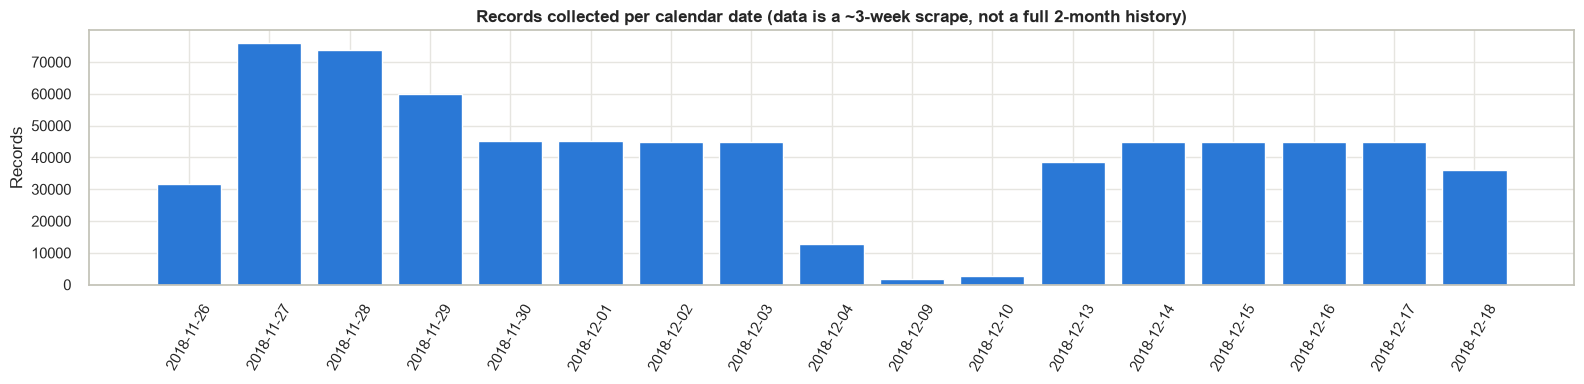

In [3]:
dt_all = pd.to_datetime(df['datetime'])
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print(f"Fully duplicated rows: {df.duplicated().sum():,} | Duplicated ride ids: {df['id'].duplicated().sum():,}")

const_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print(f"Constant (zero-information) columns: {const_cols}")
print(f"Collection window: {dt_all.min()}  ->  {dt_all.max()}  ({dt_all.dt.date.nunique()} distinct dates)")

print("\n=== Where are prices missing? ===")
display(df[df['price'].isnull()].groupby(['cab_type', 'name']).size().rename('rows_missing_price').to_frame())

card = pd.DataFrame({'dtype': df.dtypes.astype(str), 'n_unique': df.nunique(), 'pct_missing': df.isnull().mean().mul(100).round(2)})
print("\n=== Column cardinality (lowest first) ===")
display(card.sort_values('n_unique').T)

# Rides collected per calendar date -> reveals collection gaps
fig, ax = plt.subplots(figsize=(16, 4))
per_date = dt_all.dt.date.value_counts().sort_index()
ax.bar(per_date.index.astype(str), per_date.values, color=ONE, width=0.8)
ax.set_title("Records collected per calendar date (data is a ~3-week scrape, not a full 2-month history)")
ax.set_ylabel("Records"); ax.tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()


## 🔍 Cell 3 – EDA: Basic Overview
Inspect dataframe schema, summary statistics, missing values, cab provider proportions, and vehicle categories.

In [4]:
# EDA: Basic Overview
print("=== Dataset Information ===")
df.info(verbose=False, memory_usage='deep')

print("=== Target & Numerical Statistics ===")
display(df[['price', 'distance', 'surge_multiplier', 'temperature', 'humidity', 'windSpeed', 'visibility']].describe())

print("=== Missing Value Counts (Top 10 Attributes) ===")
missing_summary = df.isnull().sum()
display(missing_summary[missing_summary > 0])

print("=== Cab Type (Platform) Distribution ===")
cab_dist = df['cab_type'].value_counts()
display(cab_dist)

print("=== Unique Ride Service Classes ===")
unique_names = df['name'].unique().tolist()
print(unique_names)

print("=== Service Classes by Platform ===")
display(pd.crosstab(df['cab_type'], df['name']))

=== Dataset Information ===


<class 'pandas.DataFrame'>
RangeIndex: 693071 entries, 0 to 693070
Columns: 57 entries, id to apparentTemperatureMaxTime
dtypes: float64(29), int64(17), str(11)
memory usage: 725.1 MB
=== Target & Numerical Statistics ===


,price,distance,surge_multiplier,temperature,humidity,windSpeed,visibility
count,637976.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000
mean,16.545125,2.189430,1.013870,39.584388,0.741119,6.186253,8.467970
std,9.324359,1.138937,0.091641,6.726084,0.138595,3.148223,2.602888
min,2.500000,0.020000,1.000000,18.910000,0.380000,0.450000,0.717000
25%,9.000000,1.280000,1.000000,36.450000,0.640000,3.410000,8.432000
50%,13.500000,2.160000,1.000000,40.490000,0.710000,5.910000,9.880000
75%,22.500000,2.920000,1.000000,43.580000,0.880000,8.410000,9.996000
max,97.500000,7.860000,3.000000,57.220000,0.960000,15.000000,10.000000


=== Missing Value Counts (Top 10 Attributes) ===


price    55095
dtype: int64

=== Cab Type (Platform) Distribution ===


cab_type
Uber    385663
Lyft    307408
Name: count, dtype: int64

=== Unique Ride Service Classes ===
['Shared', 'Lux', 'Lyft', 'Lux Black XL', 'Lyft XL', 'Lux Black', 'UberXL', 'Black', 'UberX', 'WAV', 'Black SUV', 'UberPool', 'Taxi']
=== Service Classes by Platform ===


name,Black,Black SUV,Lux,Lux Black,Lux Black XL,Lyft,Lyft XL,Shared,Taxi,UberPool,UberX,UberXL,WAV
cab_type,,,,,,,,,,,,,
Lyft,0,0,51235,51235,51235,51235,51235,51233,0,0,0,0,0
Uber,55095,55096,0,0,0,0,0,0,55095,55091,55094,55096,55096


## 💰 Cell 4 – EDA: Price Distribution & Target Analysis
Clean missing price records (unpriced municipal taxi rides) and analyze target distribution, price dispersion across platforms, vehicle tiers, and surge multipliers.

Dropped 55,095 unpriced Taxi rows. Remaining valid records: 637,976


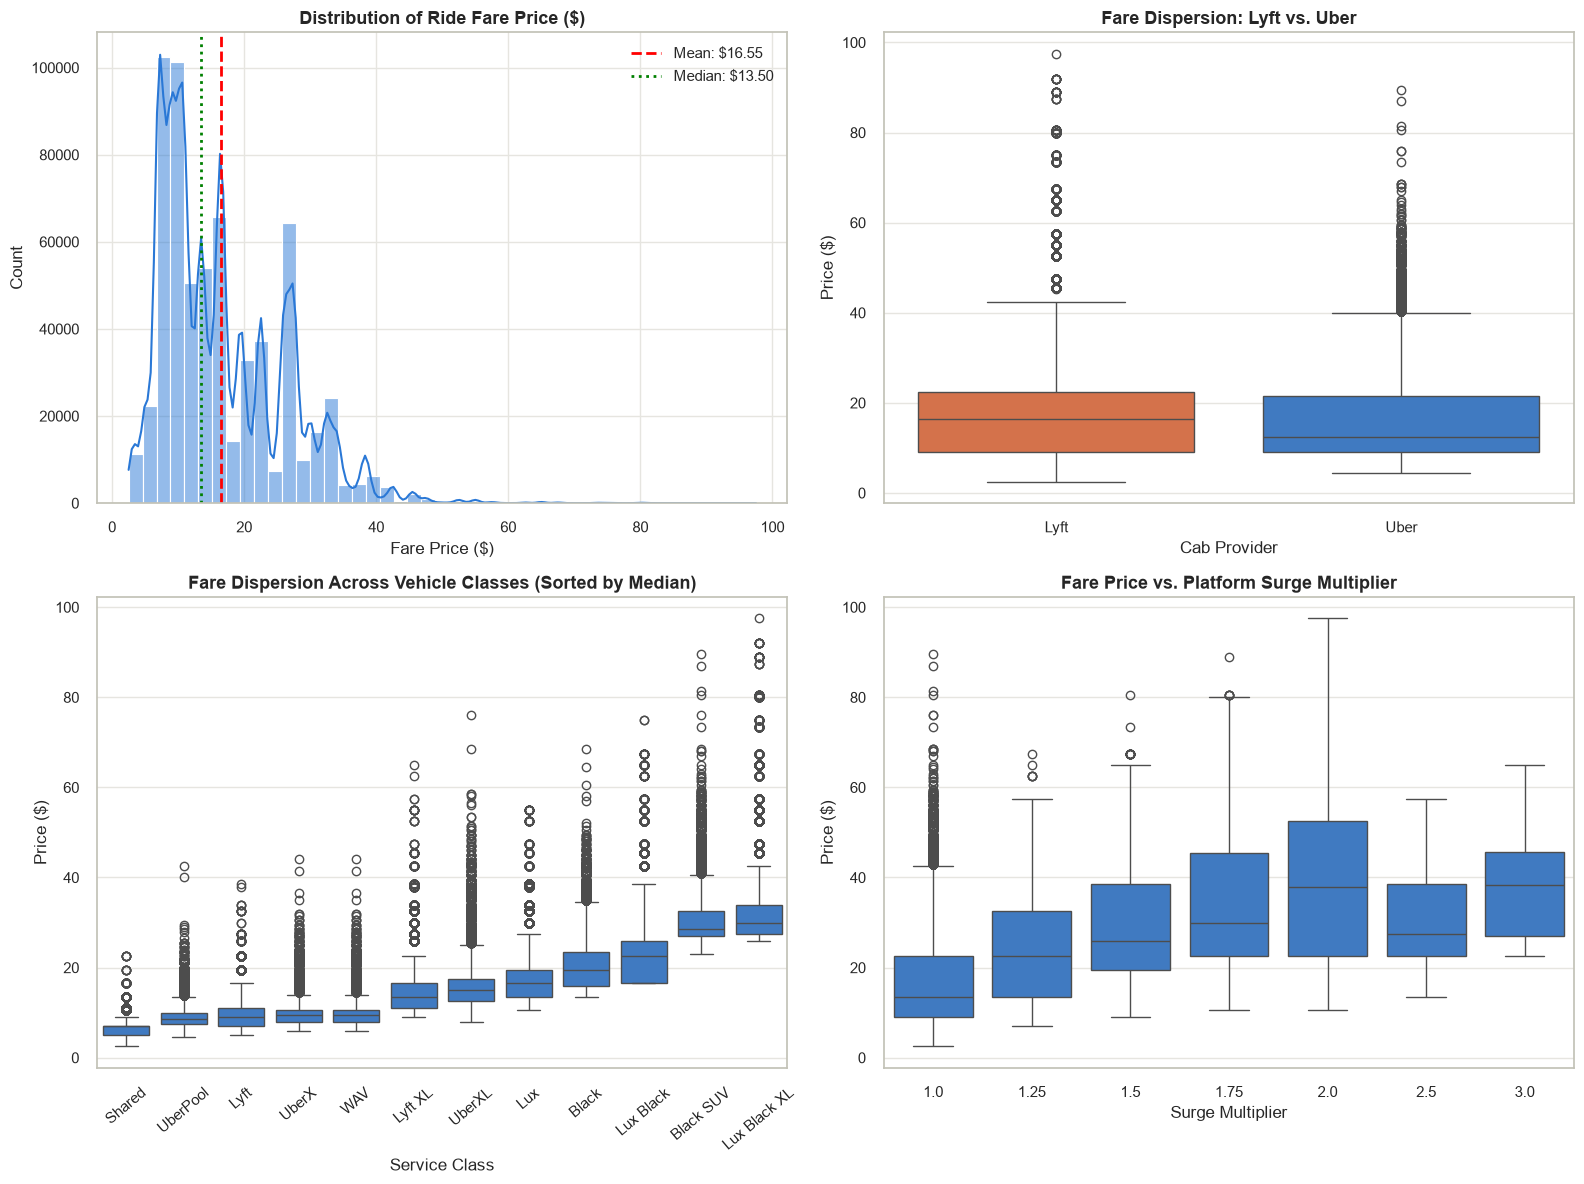

In [5]:
# EDA: Price Distribution & Target Analysis
# Remove rows where price is null (Taxi rides)
initial_count = len(df)
df = df.dropna(subset=['price']).copy()
dropped_count = initial_count - len(df)
print(f"Dropped {dropped_count:,} unpriced Taxi rows. Remaining valid records: {len(df):,}")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Price Histogram + KDE
sns.histplot(df['price'], bins=45, kde=True, color=ONE, ax=axes[0, 0])
axes[0, 0].axvline(df['price'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: ${df['price'].mean():.2f}")
axes[0, 0].axvline(df['price'].median(), color='green', linestyle=':', linewidth=2, label=f"Median: ${df['price'].median():.2f}")
axes[0, 0].set_title("Distribution of Ride Fare Price ($)", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Fare Price ($)")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend()

# 2. Box plot: price by cab_type
sns.boxplot(data=df, x='cab_type', y='price', palette=PLATFORM, ax=axes[0, 1])
axes[0, 1].set_title("Fare Dispersion: Lyft vs. Uber", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("Cab Provider")
axes[0, 1].set_ylabel("Price ($)")

# 3. Box plot: price by name (ride type)
ride_order = df.groupby('name')['price'].median().sort_values().index
sns.boxplot(data=df, x='name', y='price', order=ride_order, color=ONE, ax=axes[1, 0])
axes[1, 0].set_title("Fare Dispersion Across Vehicle Classes (Sorted by Median)", fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel("Service Class")
axes[1, 0].set_ylabel("Price ($)")
axes[1, 0].tick_params(axis='x', rotation=40)

# 4. Box plot: price by surge_multiplier
sns.boxplot(data=df, x='surge_multiplier', y='price', color=ONE, ax=axes[1, 1])
axes[1, 1].set_title("Fare Price vs. Platform Surge Multiplier", fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel("Surge Multiplier")
axes[1, 1].set_ylabel("Price ($)")

plt.tight_layout()
plt.show()

## 📐 Cell 4b – Target Deep-Dive: Shape, Skew & Outliers *(new)*
Price is right-skewed. Check whether a log transform normalises it, and whether the extreme fares are errors or real premium/surge rides.

Skewness: 1.046 | Excess kurtosis: 1.225
log1p(price) skewness: -0.003


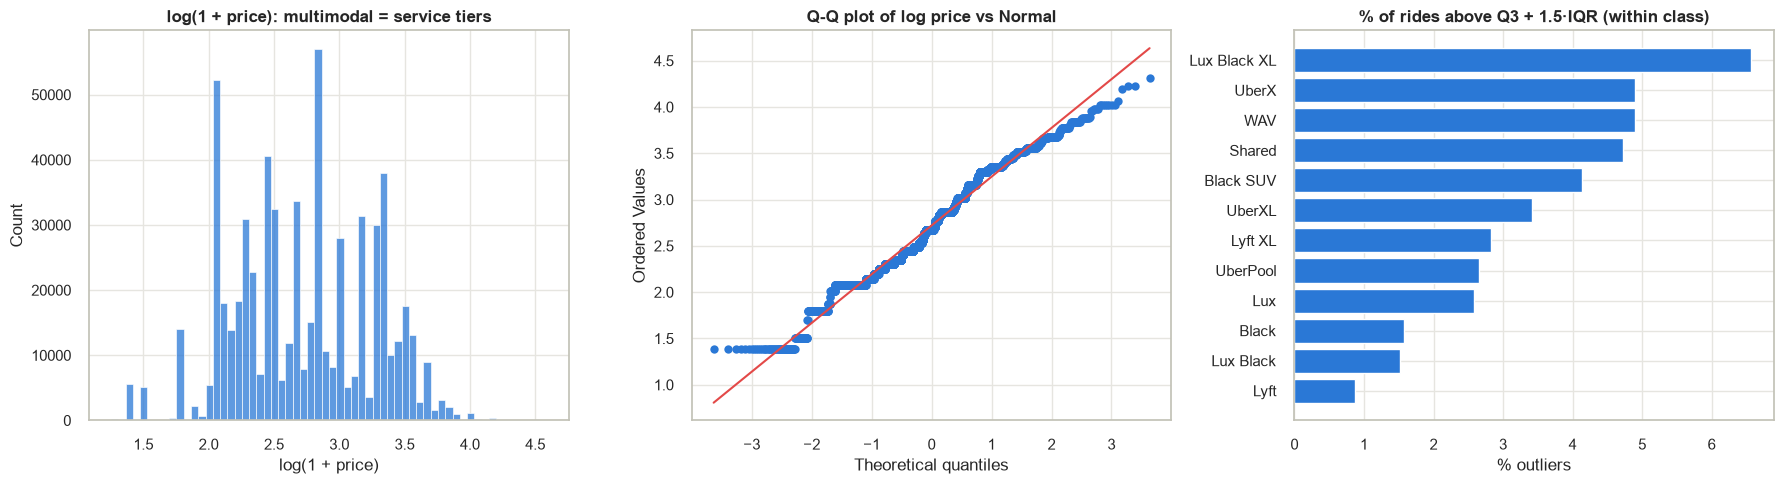

Most expensive rides - are they errors?


,cab_type,name,source,destination,distance,surge_multiplier,price
597071,Lyft,Lux Black XL,Financial District,Fenway,4.43,2.0,97.5
28083,Lyft,Lux Black XL,Fenway,Financial District,3.89,2.0,92.0
75919,Lyft,Lux Black XL,Boston University,Financial District,3.75,2.0,92.0
271719,Lyft,Lux Black XL,Financial District,Boston University,5.39,2.0,92.0
280566,Lyft,Lux Black XL,Financial District,Boston University,5.39,2.0,92.0
301021,Lyft,Lux Black XL,Financial District,Boston University,5.36,2.0,92.0
440000,Lyft,Lux Black XL,Financial District,Boston University,5.37,2.0,92.0
515785,Lyft,Lux Black XL,Boston University,Financial District,3.75,2.0,92.0


Share of within-class outliers that are surged rides: 25.8%  (vs 3.3% overall)


In [6]:
p = df['price']
print(f"Skewness: {p.skew():.3f} | Excess kurtosis: {p.kurt():.3f}")
print(f"log1p(price) skewness: {np.log1p(p).skew():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(np.log1p(p), bins=60, color=ONE, ax=axes[0])
axes[0].set_title("log(1 + price): multimodal = service tiers"); axes[0].set_xlabel("log(1 + price)")

stats.probplot(np.log1p(p.sample(5000, random_state=42)), dist='norm', plot=axes[1])
axes[1].get_lines()[0].set_color(ONE); axes[1].get_lines()[1].set_color('#e34948')
axes[1].set_title("Q-Q plot of log price vs Normal")

# IQR outlier share within each service class (outliers relative to their own tier)
q = df.groupby('name')['price'].quantile([0.25, 0.75]).unstack()
iqr = q[0.75] - q[0.25]
upper = (q[0.75] + 1.5 * iqr).reindex(df['name']).values
out_share = (df['price'].values > upper)
out_df = pd.Series(out_share, index=df.index).groupby(df['name']).mean().mul(100).sort_values()
axes[2].barh(out_df.index, out_df.values, color=ONE)
axes[2].set_title("% of rides above Q3 + 1.5·IQR (within class)"); axes[2].set_xlabel("% outliers")
plt.tight_layout(); plt.show()

print("Most expensive rides - are they errors?")
display(df.nlargest(8, 'price')[['cab_type', 'name', 'source', 'destination', 'distance', 'surge_multiplier', 'price']])
print("Share of within-class outliers that are surged rides:",
      f"{(df.loc[out_share, 'surge_multiplier'] > 1).mean()*100:.1f}%  (vs {(df['surge_multiplier'] > 1).mean()*100:.1f}% overall)")


## 🧮 Cell 4c – Reverse-Engineering the Tariff: Base Fare + Per-Mile Rate *(new)*
If fares are set by a formula `price ≈ (base + rate × distance) × surge`, a simple linear fit **per service class** (on non-surged rides) should explain most of the variance. This is the most important structural fact in the dataset.

,cab_type,service,rides,base_fare_$,per_mile_$,R2_within_class,median_price_$
0,Uber,UberPool,55091,6.13,1.20,0.450,8.5
1,Lyft,Shared,51233,3.31,1.25,0.412,7.0
2,Uber,UberX,55094,6.40,1.54,0.540,9.5
3,Uber,WAV,55096,6.40,1.54,0.540,9.5
4,Lyft,Lyft,47040,5.58,1.70,0.807,9.0
5,Uber,UberXL,55096,9.07,3.02,0.618,15.0
6,Lyft,Lyft XL,47040,7.79,3.19,0.864,13.5
7,Uber,Black SUV,55096,22.57,3.52,0.737,28.5
8,Uber,Black,55095,12.12,3.84,0.834,19.5
9,Lyft,Lux,47040,8.77,3.84,0.891,16.5


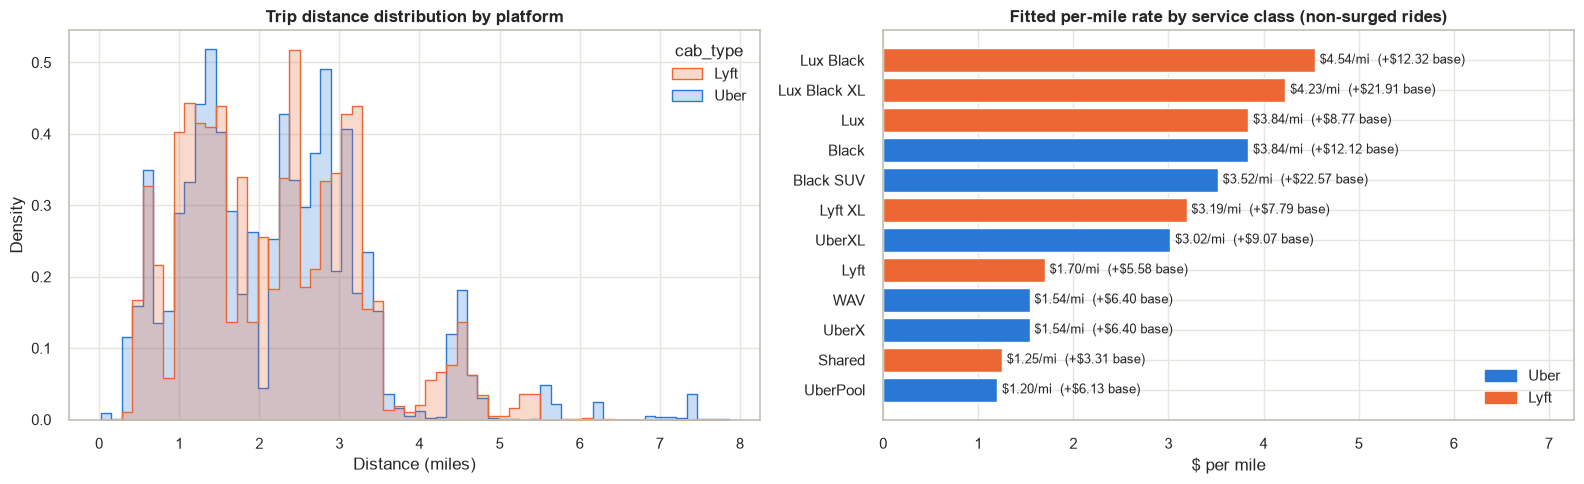

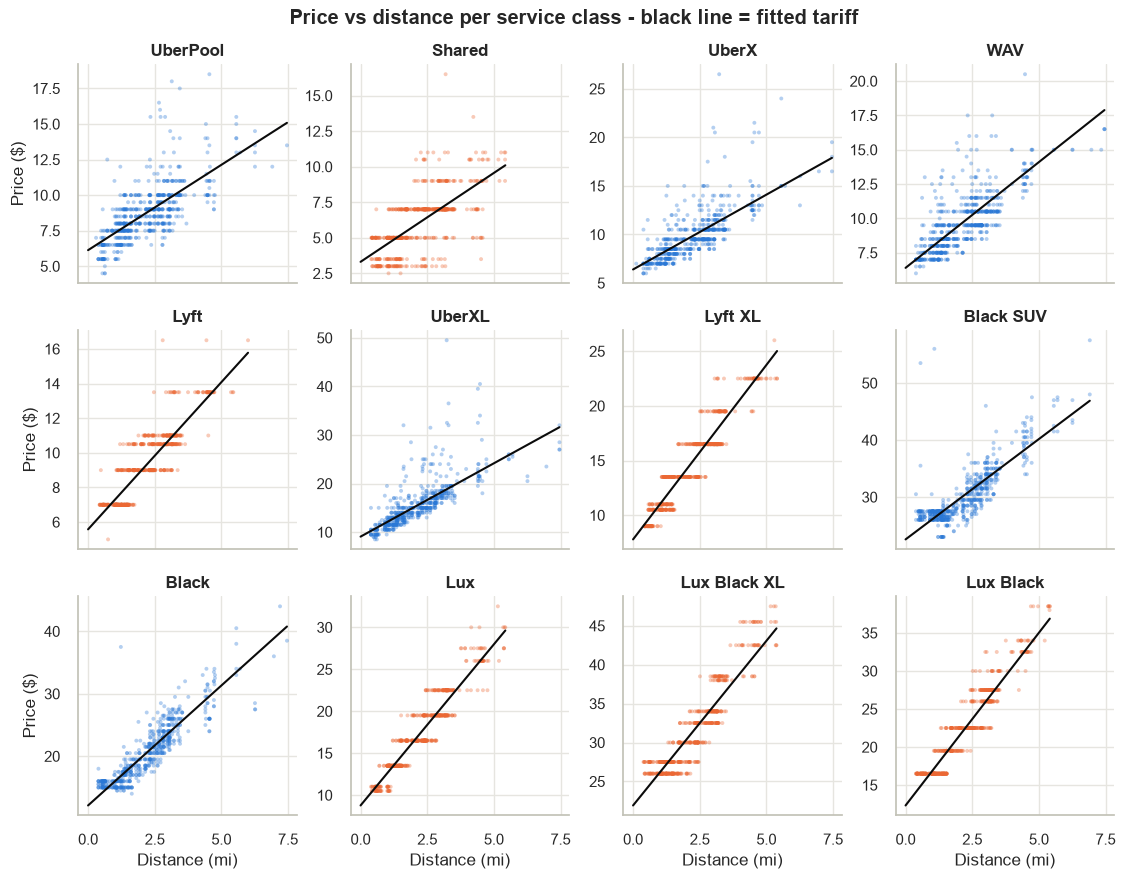

In [7]:
base_rides = df[df['surge_multiplier'] == 1.0]
rows = []
for (cab, name), g in base_rides.groupby(['cab_type', 'name']):
    fit = stats.linregress(g['distance'], g['price'])
    rows.append({'cab_type': cab, 'service': name, 'rides': len(g),
                 'base_fare_$': round(fit.intercept, 2), 'per_mile_$': round(fit.slope, 2),
                 'R2_within_class': round(fit.rvalue ** 2, 3), 'median_price_$': g['price'].median()})
tariff = pd.DataFrame(rows).sort_values('per_mile_$').reset_index(drop=True)
display(tariff)
TARIFF = tariff.set_index('service')[['base_fare_$', 'per_mile_$']]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=df, x='distance', hue='cab_type', bins=60, element='step', stat='density',
             common_norm=False, palette=PLATFORM, ax=axes[0])
axes[0].set_title("Trip distance distribution by platform"); axes[0].set_xlabel("Distance (miles)")

colors = tariff['cab_type'].map(PLATFORM)
axes[1].barh(tariff['service'], tariff['per_mile_$'], color=colors)
for i, r in tariff.iterrows():
    axes[1].text(r['per_mile_$'] + 0.05, i, f"\\${r['per_mile_$']:.2f}/mi  (+\\${r['base_fare_$']:.2f} base)", va='center', fontsize=9)
axes[1].set_title("Fitted per-mile rate by service class (non-surged rides)")
axes[1].set_xlabel("$ per mile"); axes[1].set_xlim(0, tariff['per_mile_$'].max() * 1.6)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=c, label=k) for k, c in PLATFORM.items()], loc='lower right')
plt.tight_layout(); plt.show()

# Small multiples: price vs distance per class with fitted tariff line
order = tariff['service'].tolist()
samp = base_rides.groupby('name').sample(n=600, random_state=42)
g = sns.FacetGrid(samp, col='name', col_order=order, col_wrap=4, height=2.8, sharey=False)
def _panel(data, **kw):
    ax = plt.gca(); name = data['name'].iloc[0]; cab = data['cab_type'].iloc[0]
    ax.scatter(data['distance'], data['price'], s=8, alpha=0.35, color=PLATFORM[cab], edgecolors='none')
    xs = np.linspace(0, data['distance'].max(), 20)
    ax.plot(xs, TARIFF.loc[name, 'base_fare_$'] + TARIFF.loc[name, 'per_mile_$'] * xs, color='#0b0b0b', lw=1.5)
g.map_dataframe(_panel)
g.set_titles("{col_name}"); g.set_axis_labels("Distance (mi)", "Price ($)")
g.fig.suptitle("Price vs distance per service class - black line = fitted tariff", y=1.02, fontweight='bold')
plt.show()


## ⚖️ Cell 4d – Uber vs Lyft, Tier-Matched *(new)*
The original platform box plot mixes tiers (Uber has a cheap Taxi/WAV mix, Lyft has Lux). A fair comparison matches equivalent products and compares **price per mile** on non-surged rides.

,tier,Uber_median_$,Lyft_median_$,Uber_mean_$,Lyft_mean_$,diff_mean_$ (Lyft-Uber),MannWhitney_p
0,Shared,8.5,7.0,8.82,6.06,-2.76,0.000000e+00
1,Standard,9.5,9.0,9.85,9.32,-0.52,2.002803e-239
2,XL,15.0,13.5,15.86,14.83,-1.03,1.578550e-252
3,Premium,19.5,22.5,20.68,22.27,1.60,0.000000e+00
4,Premium XL,29.0,30.0,30.39,31.18,0.78,6.396014e-104


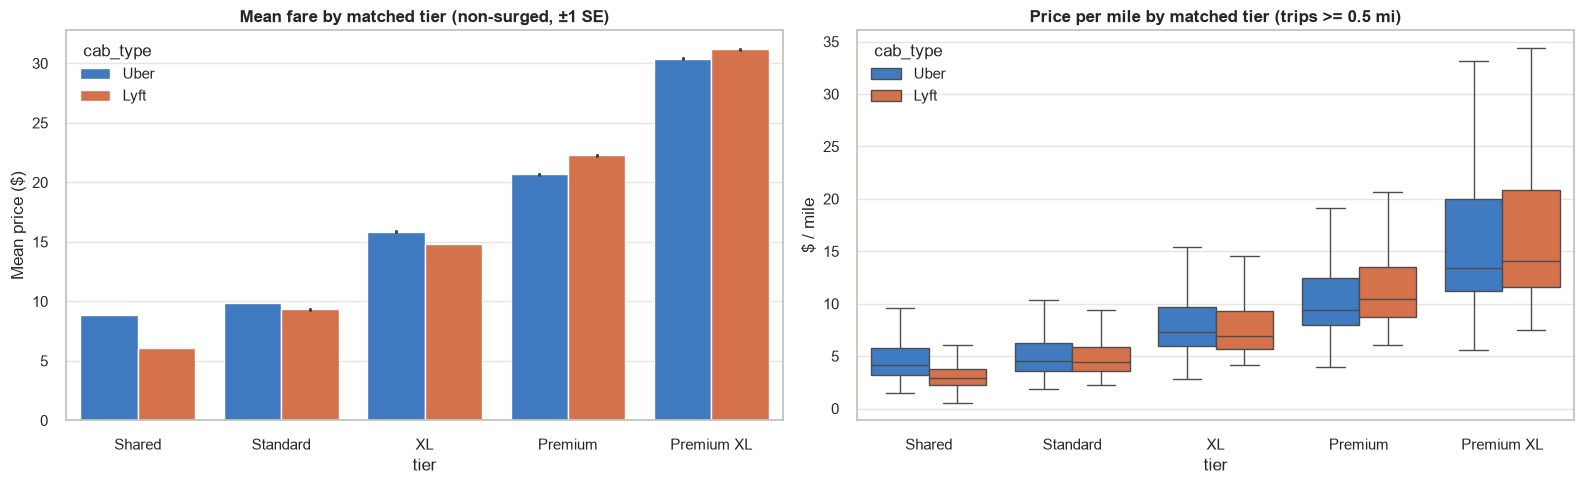

In [8]:
TIER = {'UberPool': 'Shared', 'Shared': 'Shared', 'UberX': 'Standard', 'Lyft': 'Standard',
        'UberXL': 'XL', 'Lyft XL': 'XL', 'Black': 'Premium', 'Lux Black': 'Premium',
        'Black SUV': 'Premium XL', 'Lux Black XL': 'Premium XL'}
tier_order = ['Shared', 'Standard', 'XL', 'Premium', 'Premium XL']
cmp = base_rides[base_rides['name'].isin(TIER) & (base_rides['distance'] >= 0.5)].copy()
cmp['tier'] = cmp['name'].map(TIER)
cmp['price_per_mile'] = cmp['price'] / cmp['distance']

test_rows = []
for t in tier_order:
    u = cmp.loc[(cmp.tier == t) & (cmp.cab_type == 'Uber'), 'price']
    l = cmp.loc[(cmp.tier == t) & (cmp.cab_type == 'Lyft'), 'price']
    stat, pval = stats.mannwhitneyu(u, l)
    test_rows.append({'tier': t, 'Uber_median_$': u.median(), 'Lyft_median_$': l.median(),
                      'Uber_mean_$': round(u.mean(), 2), 'Lyft_mean_$': round(l.mean(), 2),
                      'diff_mean_$ (Lyft-Uber)': round(l.mean() - u.mean(), 2), 'MannWhitney_p': pval})
display(pd.DataFrame(test_rows))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=cmp, x='tier', y='price', hue='cab_type', order=tier_order, hue_order=['Uber', 'Lyft'],
            palette=PLATFORM, estimator='mean', errorbar='se', ax=axes[0])
axes[0].set_title("Mean fare by matched tier (non-surged, ±1 SE)"); axes[0].set_ylabel("Mean price ($)")
sns.boxplot(data=cmp, x='tier', y='price_per_mile', hue='cab_type', order=tier_order, hue_order=['Uber', 'Lyft'],
            palette=PLATFORM, showfliers=False, ax=axes[1])
axes[1].set_title("Price per mile by matched tier (trips >= 0.5 mi)"); axes[1].set_ylabel("$ / mile")
plt.tight_layout(); plt.show()


## 📈 Cell 4e – Surge Pricing Deep-Dive *(new)*
Who surges, when, where, and does the fare actually scale with the multiplier?

% of rides with surge > 1.0 by platform:


,pct_surged
cab_type,
Lyft,6.82
Uber,0.00


Distinct surge levels by platform: {'Lyft': array([1.  , 1.25, 2.5 , 2.  , 1.75, 1.5 , 3.  ]), 'Uber': array([1.])}


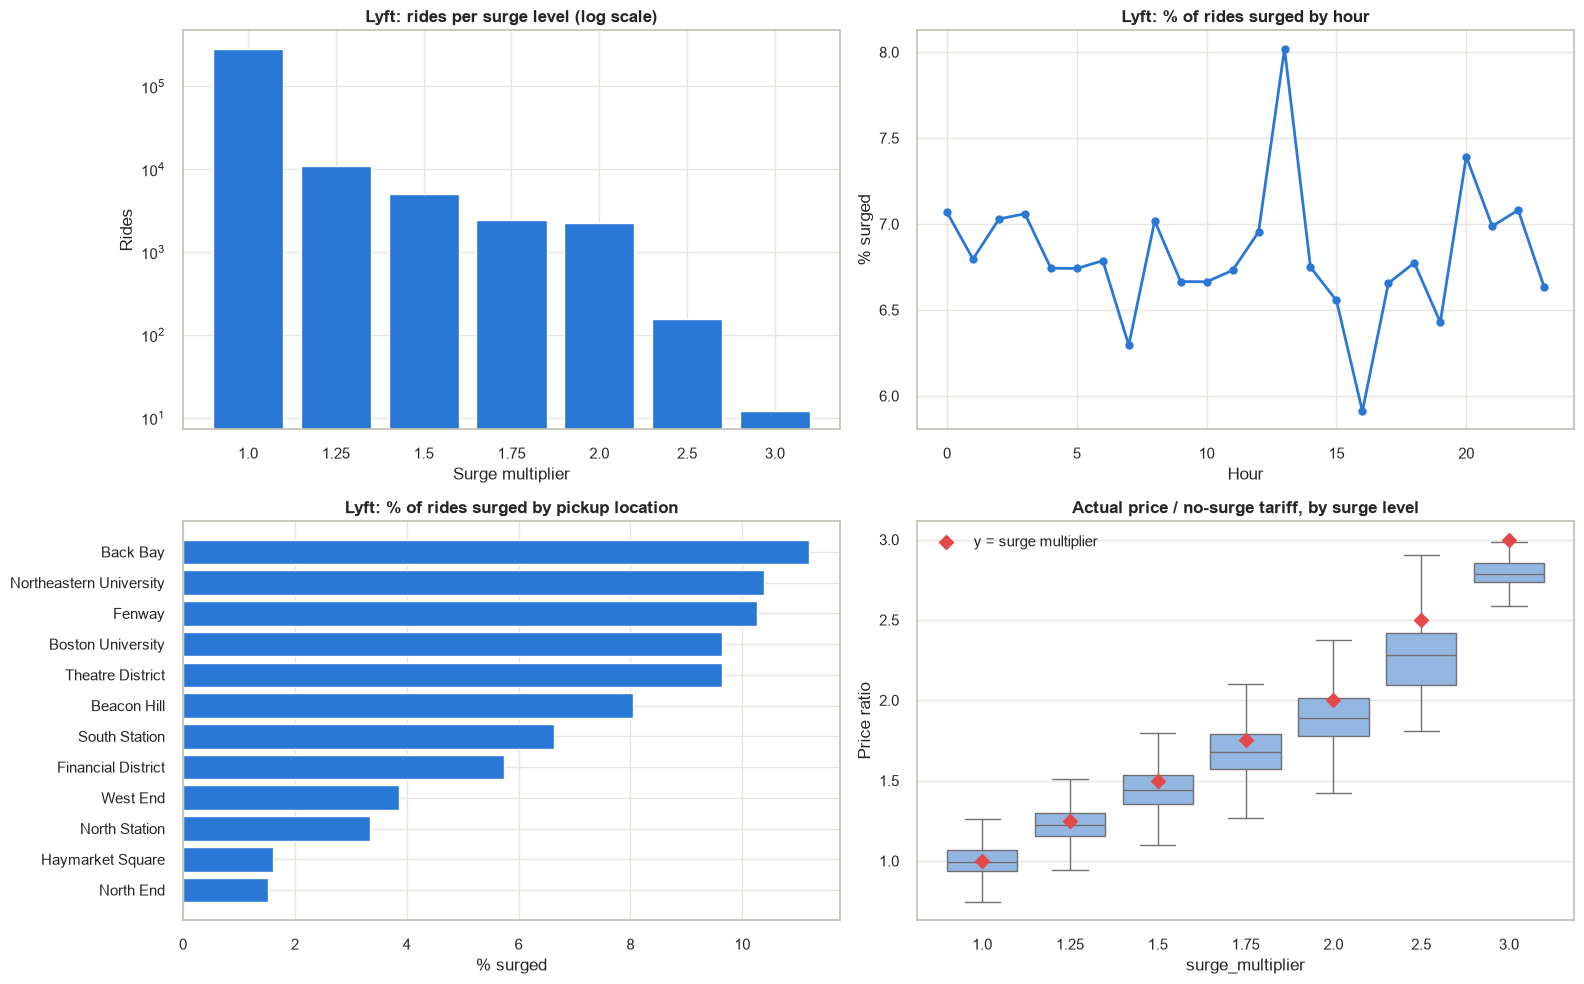

% surged by Lyft product:


,pct_surged
name,
Lux,8.19
Lux Black,8.19
Lux Black XL,8.19
Lyft,8.19
Lyft XL,8.19
Shared,0.00


% surged by weather icon:


,pct_surged
icon,
clear-day,7.12
clear-night,7.10
cloudy,6.57
fog,7.85
partly-cloudy-day,7.01
partly-cloudy-night,6.96
rain,6.60


In [9]:
surge_share = df.groupby('cab_type')['surge_multiplier'].apply(lambda s: (s > 1).mean() * 100)
print("% of rides with surge > 1.0 by platform:"); display(surge_share.round(2).to_frame('pct_surged'))
print("Distinct surge levels by platform:", df.groupby('cab_type')['surge_multiplier'].unique().to_dict())

lyft = df[df['cab_type'] == 'Lyft'].copy()
lyft['hour_'] = pd.to_datetime(lyft['datetime']).dt.hour
lyft['surged'] = lyft['surge_multiplier'] > 1

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
lvl = lyft['surge_multiplier'].value_counts().sort_index()
axes[0, 0].bar(lvl.index.astype(str), lvl.values, color=ONE); axes[0, 0].set_yscale('log')
axes[0, 0].set_title("Lyft: rides per surge level (log scale)"); axes[0, 0].set_xlabel("Surge multiplier"); axes[0, 0].set_ylabel("Rides")

by_hour = lyft.groupby('hour_')['surged'].mean() * 100
axes[0, 1].plot(by_hour.index, by_hour.values, marker='o', color=ONE, lw=2)
axes[0, 1].set_title("Lyft: % of rides surged by hour"); axes[0, 1].set_xlabel("Hour"); axes[0, 1].set_ylabel("% surged")

by_src = (lyft.groupby('source')['surged'].mean() * 100).sort_values()
axes[1, 0].barh(by_src.index, by_src.values, color=ONE)
axes[1, 0].set_title("Lyft: % of rides surged by pickup location"); axes[1, 0].set_xlabel("% surged")

# Does price scale with surge? ratio of actual price to the no-surge tariff prediction
lyft['tariff_price'] = lyft['name'].map(TARIFF['base_fare_$']) + lyft['name'].map(TARIFF['per_mile_$']) * lyft['distance']
lyft['ratio'] = lyft['price'] / lyft['tariff_price']
sns.boxplot(data=lyft, x='surge_multiplier', y='ratio', color='#86b6ef', showfliers=False, ax=axes[1, 1])
lvls = sorted(lyft['surge_multiplier'].unique())
axes[1, 1].scatter(range(len(lvls)), lvls, color='#e34948', marker='D', s=50, zorder=5, label='y = surge multiplier')
axes[1, 1].set_title("Actual price / no-surge tariff, by surge level"); axes[1, 1].set_ylabel("Price ratio"); axes[1, 1].legend()
plt.tight_layout(); plt.show()

print("% surged by Lyft product:"); display((lyft.groupby('name')['surged'].mean() * 100).round(2).to_frame('pct_surged'))
print("% surged by weather icon:"); display((lyft.groupby(lyft['icon'].str.strip())['surged'].mean() * 100).round(2).to_frame('pct_surged'))


## ⏰ Cell 5 – EDA: Temporal Analysis
Analyze temporal patterns across hours of day, days of month, calendar months, and hour-day cross-tabulation heatmaps.

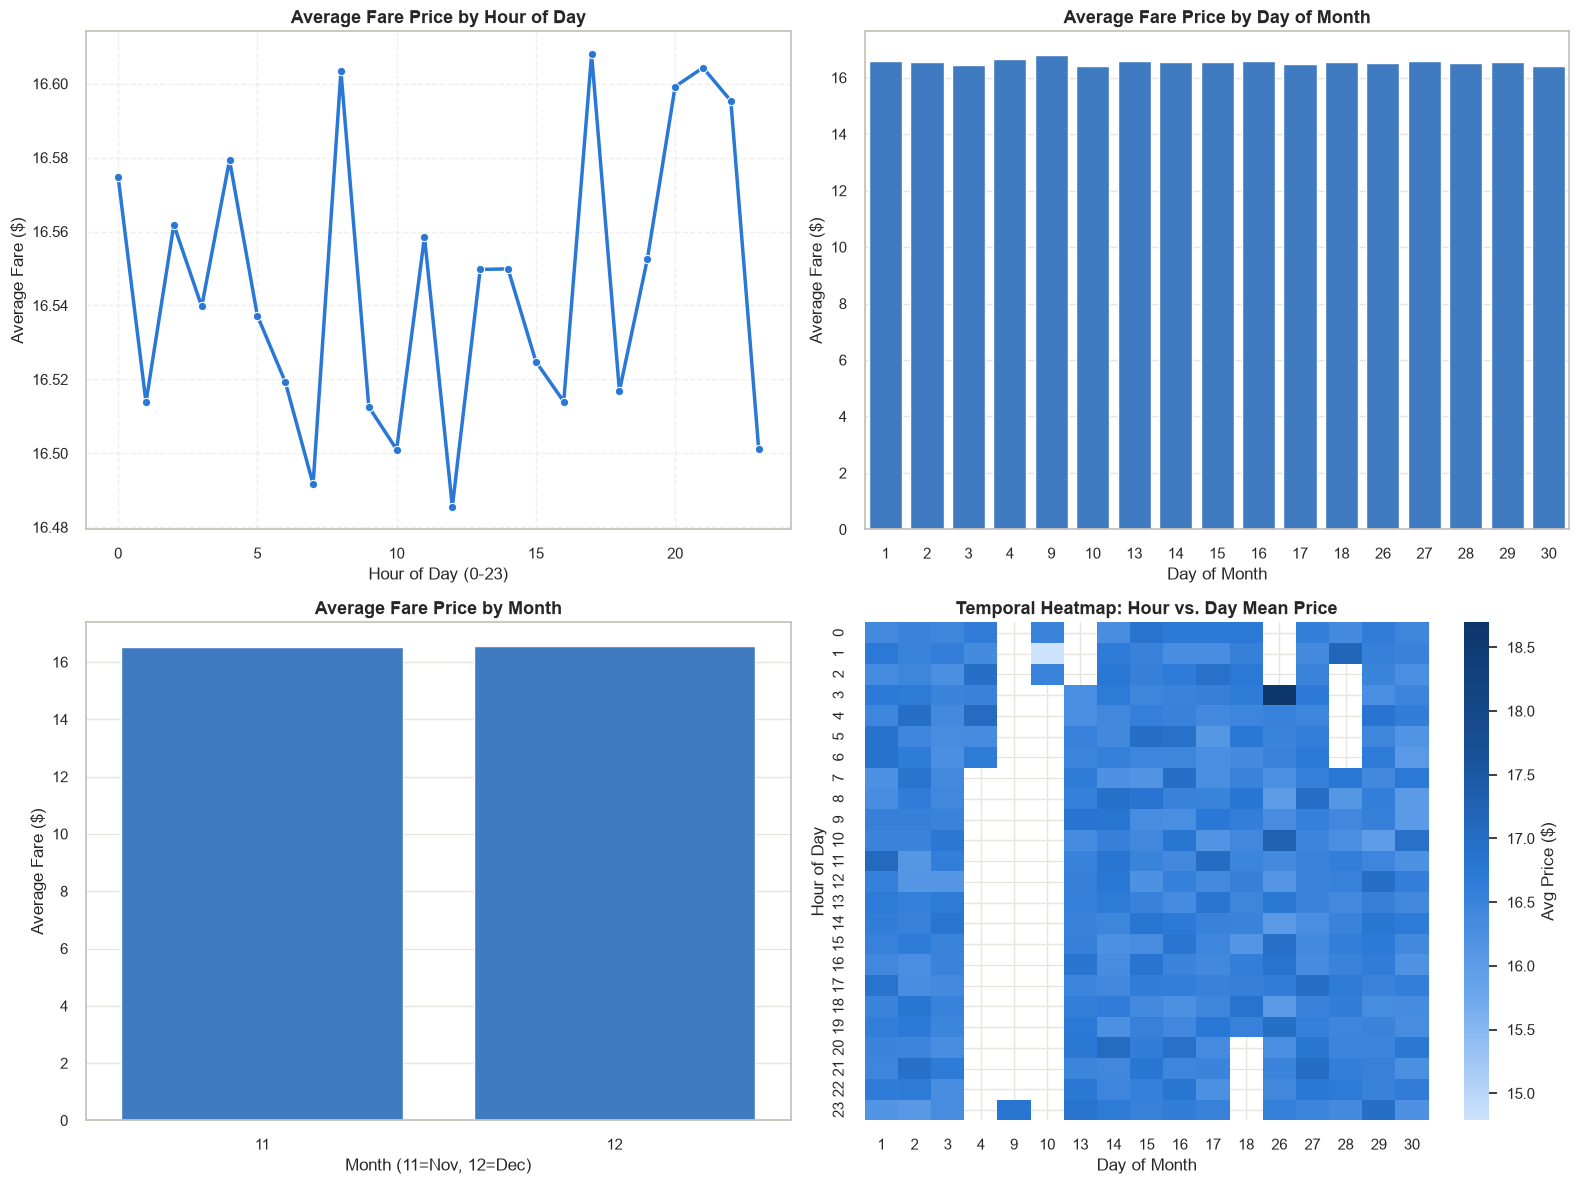

In [10]:
# EDA: Temporal Analysis
df['dt_temp'] = pd.to_datetime(df['datetime'])
df['hour_temp'] = df['dt_temp'].dt.hour
df['day_temp'] = df['dt_temp'].dt.day
df['month_temp'] = df['dt_temp'].dt.month

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Average price by hour of day (line plot)
hourly_fares = df.groupby('hour_temp')['price'].mean().reset_index()
sns.lineplot(data=hourly_fares, x='hour_temp', y='price', marker='o', color=ONE, linewidth=2.5, ax=axes[0, 0])
axes[0, 0].set_title("Average Fare Price by Hour of Day", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Hour of Day (0-23)")
axes[0, 0].set_ylabel("Average Fare ($)")
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# 2. Average price by day of month
daily_fares = df.groupby('day_temp')['price'].mean().reset_index()
sns.barplot(data=daily_fares, x='day_temp', y='price', color=ONE, ax=axes[0, 1])
axes[0, 1].set_title("Average Fare Price by Day of Month", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("Day of Month")
axes[0, 1].set_ylabel("Average Fare ($)")

# 3. Average price by month
monthly_fares = df.groupby('month_temp')['price'].mean().reset_index()
sns.barplot(data=monthly_fares, x='month_temp', y='price', color=ONE, ax=axes[1, 0])
axes[1, 0].set_title("Average Fare Price by Month", fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel("Month (11=Nov, 12=Dec)")
axes[1, 0].set_ylabel("Average Fare ($)")

# 4. Heatmap: hour vs day avg price
pivot_hd = df.pivot_table(index='hour_temp', columns='day_temp', values='price', aggfunc='mean')
sns.heatmap(pivot_hd, cmap=SEQ, ax=axes[1, 1], cbar_kws={'label': 'Avg Price ($)'})
axes[1, 1].set_title("Temporal Heatmap: Hour vs. Day Mean Price", fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel("Day of Month")
axes[1, 1].set_ylabel("Hour of Day")

# Clean temp columns
df.drop(columns=['dt_temp', 'hour_temp', 'day_temp', 'month_temp'], inplace=True, errors='ignore')

plt.tight_layout()
plt.show()

## 🗓️ Cell 5b – Hour × Weekday Structure & How Much Time Really Matters *(new)*
Average fare *looks* like it moves by hour, but the y-axis in the original line plot is zoomed in. Quantify the swing relative to the mean, and separate **ride volume** from **price**.

Hourly mean fare range: $16.49 - $16.61  (swing = 0.74% of the mean)
Kruskal-Wallis across hours: H = 7.2, p = 0.999 -> no detectable hour-of-day effect on price


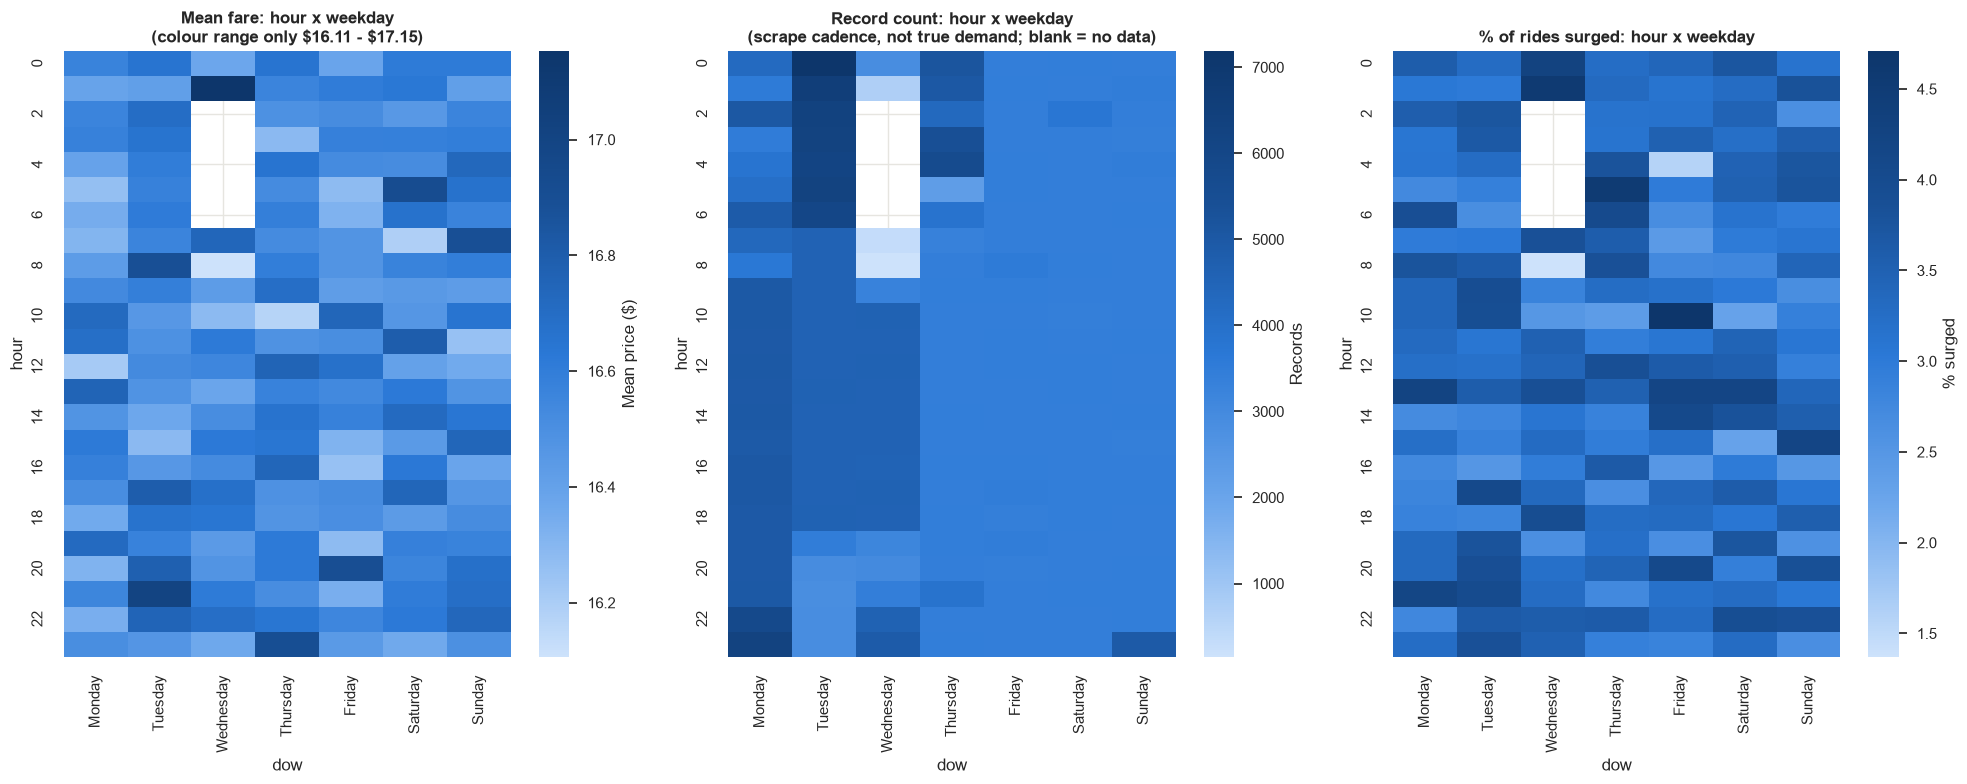

In [11]:
tmp = pd.DataFrame({'hour': dt_all.loc[df.index].dt.hour, 'dow': dt_all.loc[df.index].dt.day_name(),
                    'price': df['price'], 'surged': df['surge_multiplier'] > 1})
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hourly = tmp.groupby('hour')['price'].mean()
print(f"Hourly mean fare range: ${hourly.min():.2f} - ${hourly.max():.2f}  "
      f"(swing = {(hourly.max() - hourly.min()) / hourly.mean() * 100:.2f}% of the mean)")
kw_h = stats.kruskal(*[g.values for _, g in tmp.groupby('hour')['price']])
print(f"Kruskal-Wallis across hours: H = {kw_h.statistic:.1f}, p = {kw_h.pvalue:.3g} -> "
      + ("no detectable hour-of-day effect on price" if kw_h.pvalue > 0.05 else "statistically significant, but check the effect size above"))

fig, axes = plt.subplots(1, 3, figsize=(20, 8))
pv_price = tmp.pivot_table(index='hour', columns='dow', values='price', aggfunc='mean')[dow_order]
sns.heatmap(pv_price, cmap=SEQ, ax=axes[0], yticklabels=2, cbar_kws={'label': 'Mean price ($)'})
axes[0].set_title(f"Mean fare: hour x weekday\n(colour range only \\${pv_price.min().min():.2f} - \\${pv_price.max().max():.2f})")
pv_cnt = tmp.pivot_table(index='hour', columns='dow', values='price', aggfunc='size')[dow_order]
sns.heatmap(pv_cnt, cmap=SEQ, ax=axes[1], yticklabels=2, cbar_kws={'label': 'Records'})
axes[1].set_title("Record count: hour x weekday\n(scrape cadence, not true demand; blank = no data)")
pv_surge = tmp.pivot_table(index='hour', columns='dow', values='surged', aggfunc='mean')[dow_order] * 100
sns.heatmap(pv_surge, cmap=SEQ, ax=axes[2], yticklabels=2, cbar_kws={'label': '% surged'})
axes[2].set_title("% of rides surged: hour x weekday")
plt.tight_layout(); plt.show()
del tmp, dt_all  # free memory


## 🗺️ Cell 6 – EDA: Location & Distance Analysis
Analyze spatial corridors, distance elasticity, top revenue routes, and geographic request concentrations.

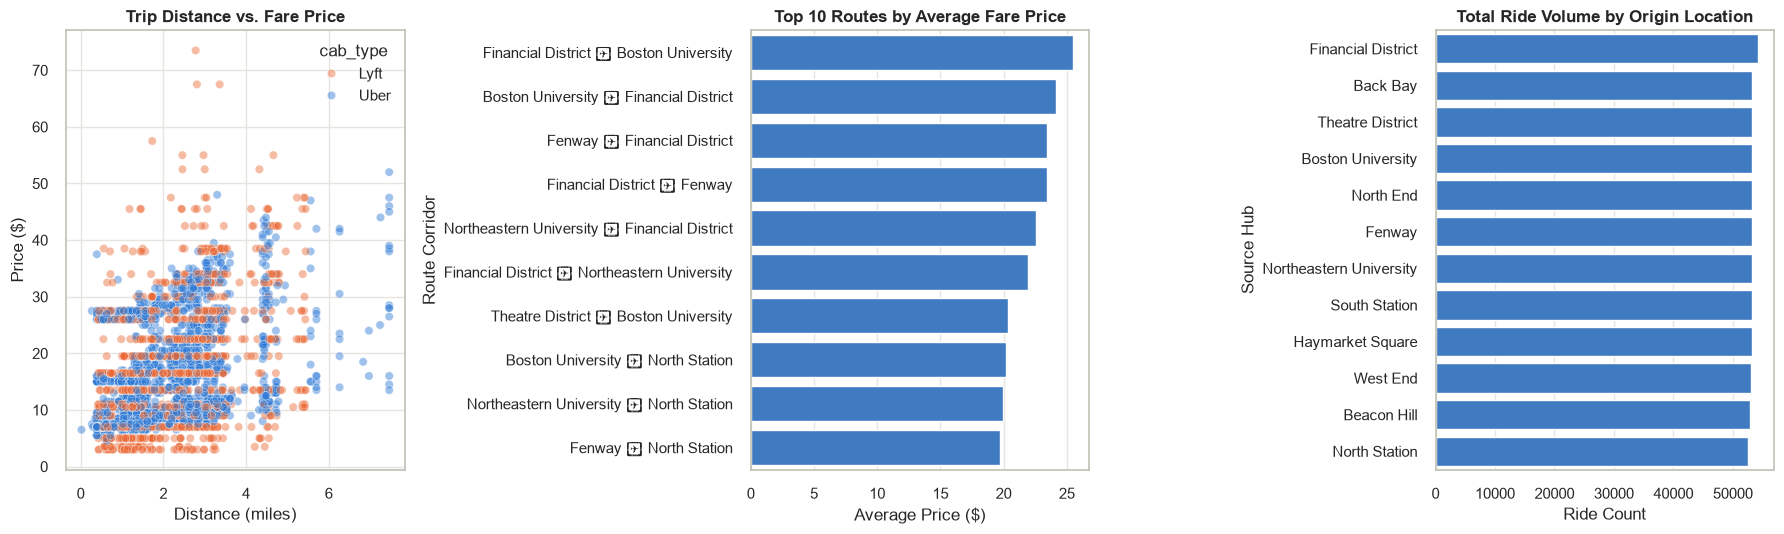

In [12]:
# EDA: Location & Distance Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Price vs Distance scatter (with hue=cab_type)
scatter_sample = df.sample(min(4000, len(df)), random_state=42)
sns.scatterplot(data=scatter_sample, x='distance', y='price', hue='cab_type', alpha=0.45, palette=PLATFORM, ax=axes[0])
axes[0].set_title("Trip Distance vs. Fare Price", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Distance (miles)")
axes[0].set_ylabel("Price ($)")

# 2. Top source and destination routes avg price bar chart
df['route'] = df['source'] + " ➔ " + df['destination']
top_routes = df.groupby('route')['price'].mean().sort_values(ascending=False).head(10).reset_index()
sns.barplot(data=top_routes, x='price', y='route', color=ONE, ax=axes[1])
axes[1].set_title("Top 10 Routes by Average Fare Price", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Average Price ($)")
axes[1].set_ylabel("Route Corridor")

# 3. Ride count by source location
source_vol = df['source'].value_counts().reset_index()
source_vol.columns = ['Source Hub', 'Ride Count']
sns.barplot(data=source_vol, x='Ride Count', y='Source Hub', color=ONE, ax=axes[2])
axes[2].set_title("Total Ride Volume by Origin Location", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Ride Count")

plt.tight_layout()
plt.show()

## 🧭 Cell 6b – Route Matrix *(new)*
Only a fixed set of origin-destination pairs exists. Expensive "top routes" in the original chart are simply the **longest** routes; normalising by distance tells the real story.

Distinct sources: 12 | destinations: 12 | observed routes: 72 of 144 possible


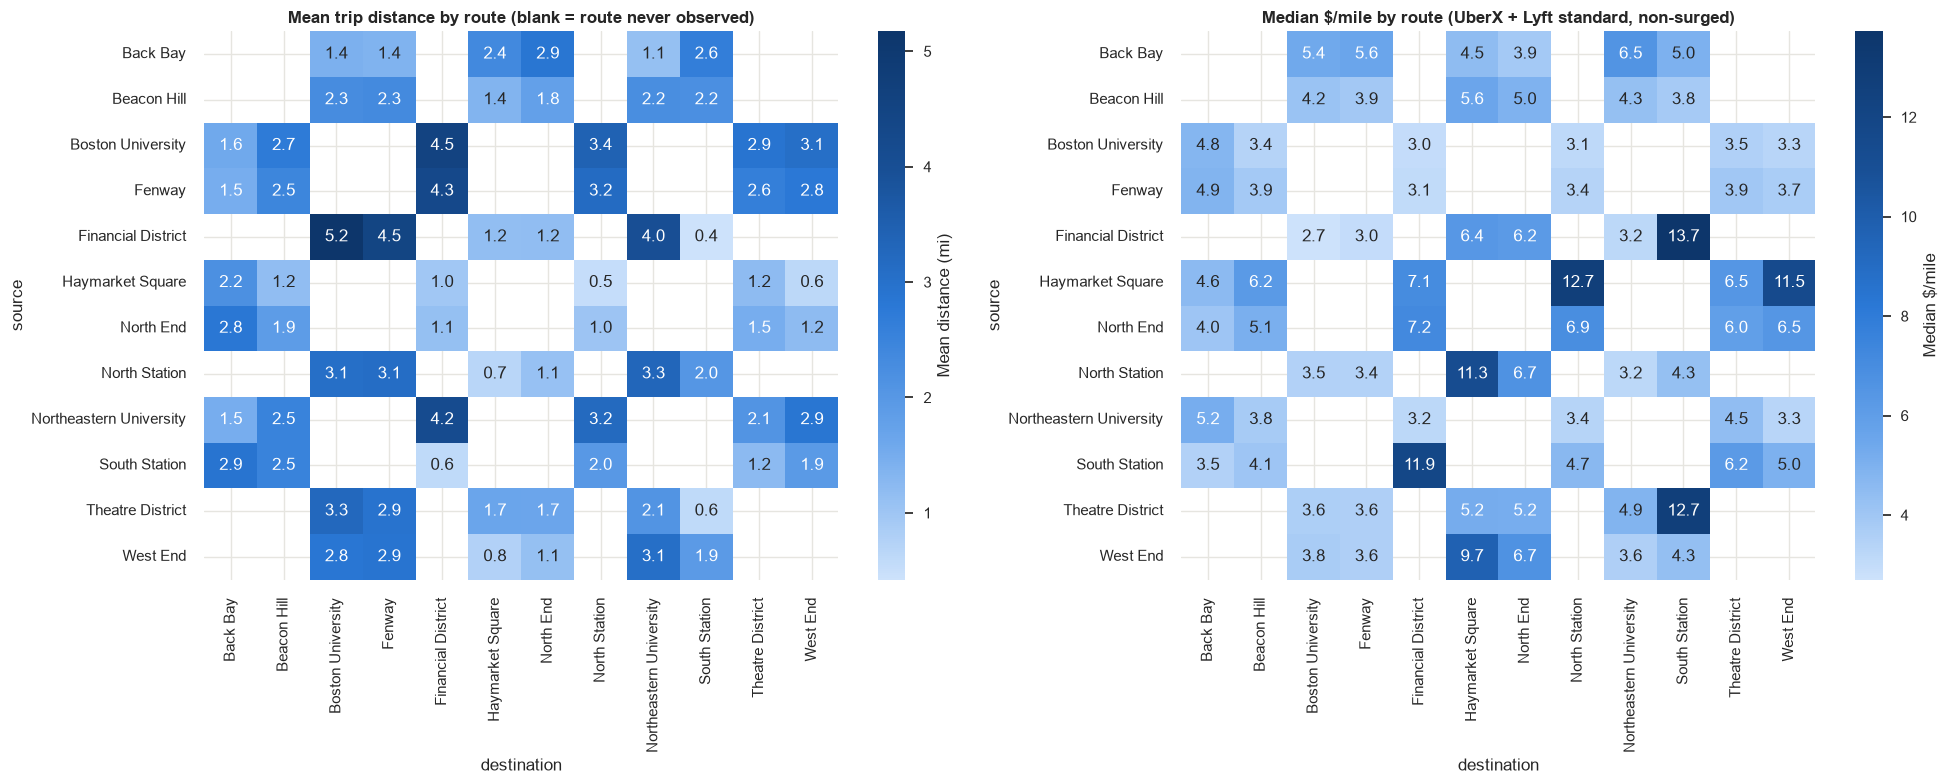

Correlation between a route's mean price and its mean distance: r = 0.987


In [13]:
print(f"Distinct sources: {df['source'].nunique()} | destinations: {df['destination'].nunique()} | "
      f"observed routes: {df.groupby(['source', 'destination']).ngroups} of {df['source'].nunique() ** 2} possible")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
m_dist = df.pivot_table(index='source', columns='destination', values='distance', aggfunc='mean')
sns.heatmap(m_dist, cmap=SEQ, annot=True, fmt='.1f', ax=axes[0], cbar_kws={'label': 'Mean distance (mi)'})
axes[0].set_title("Mean trip distance by route (blank = route never observed)")

std = base_rides[base_rides['name'].isin(['UberX', 'Lyft']) & (base_rides['distance'] >= 0.5)]
m_ppm = std.assign(ppm=std['price'] / std['distance']).pivot_table(index='source', columns='destination', values='ppm', aggfunc='median')
sns.heatmap(m_ppm, cmap=SEQ, annot=True, fmt='.1f', ax=axes[1], cbar_kws={'label': 'Median $/mile'})
axes[1].set_title("Median $/mile by route (UberX + Lyft standard, non-surged)")
plt.tight_layout(); plt.show()

rt = df.groupby('route').agg(mean_price=('price', 'mean'), mean_distance=('distance', 'mean'))
print(f"Correlation between a route's mean price and its mean distance: r = {rt['mean_price'].corr(rt['mean_distance']):.3f}")


## 🌦️ Cell 7 – EDA: Weather Impact Analysis
Assess meteorological correlation with ride pricing (DarkSky temperature, humidity, wind speed, precipitation, and conditions).

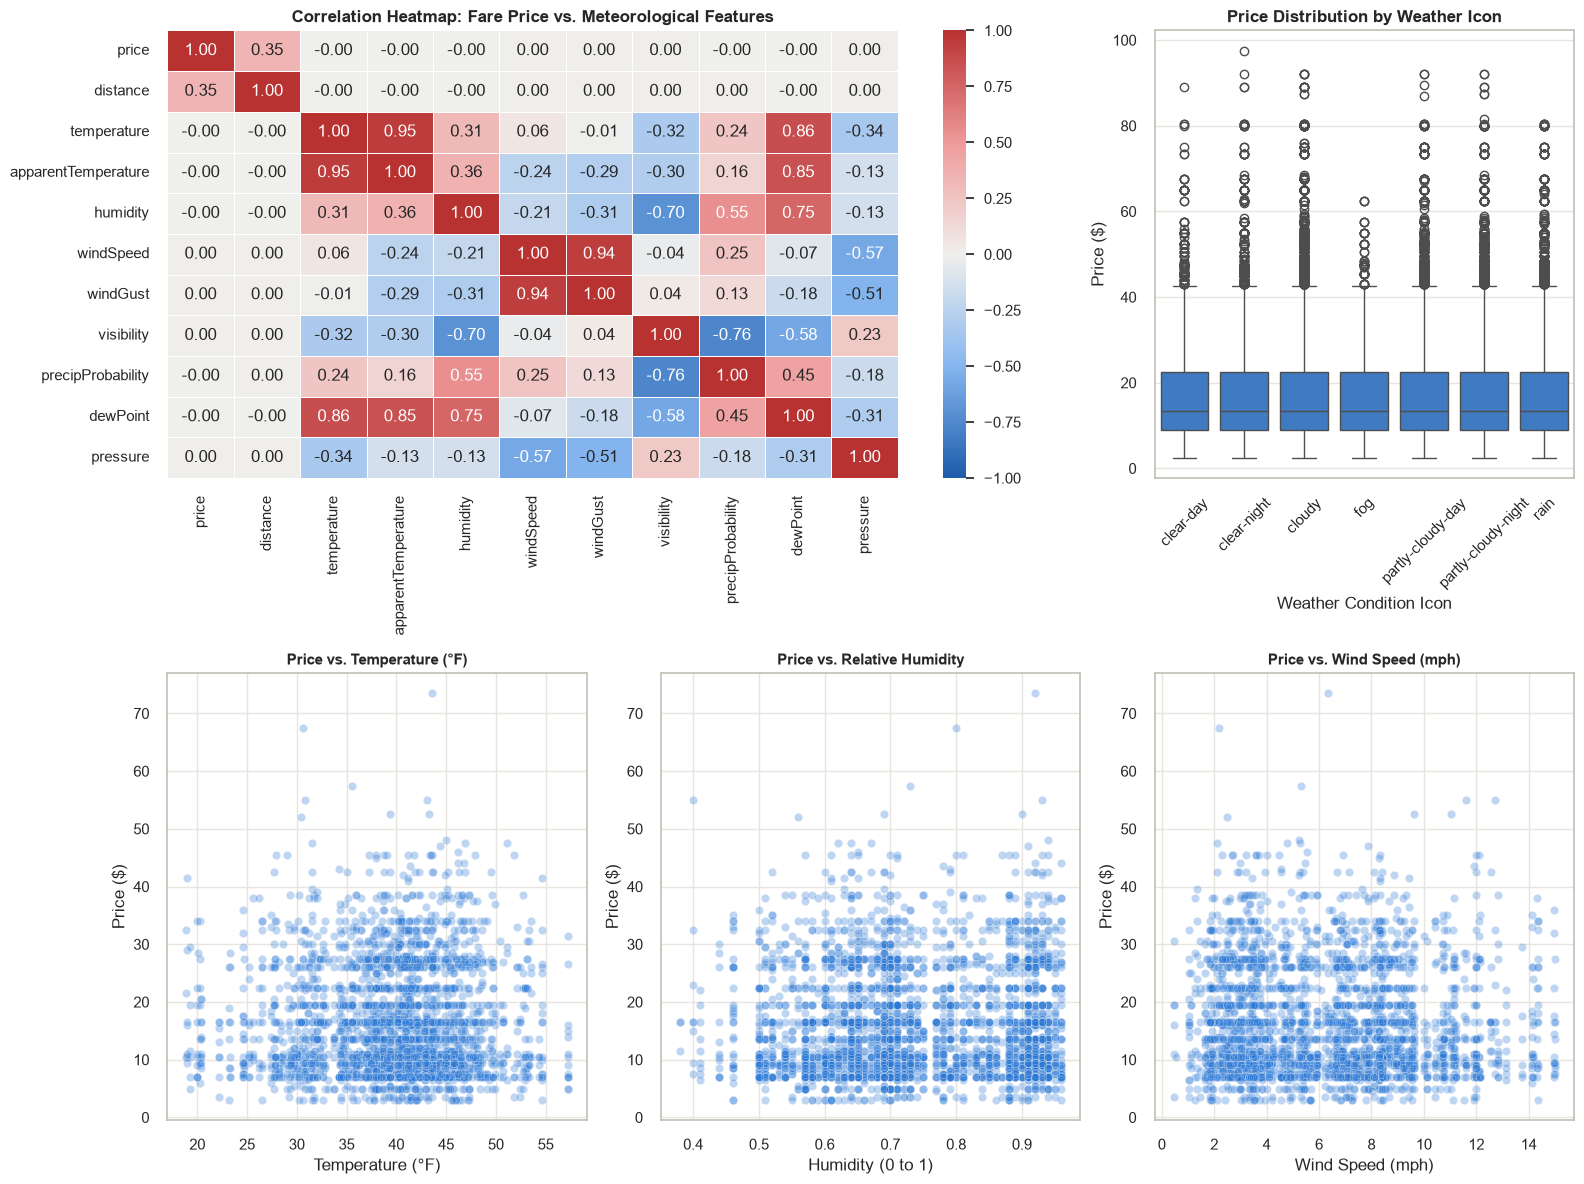

In [14]:
# EDA: Weather Impact Analysis
fig = plt.figure(figsize=(16, 12))

# 1. Correlation heatmap of weather features vs price
ax1 = plt.subplot2grid((2, 3), (0, 0), colspan=2)
weather_features = ['price', 'distance', 'temperature', 'apparentTemperature', 'humidity', 'windSpeed', 'windGust', 'visibility', 'precipProbability', 'dewPoint', 'pressure']
w_cols = [c for c in weather_features if c in df.columns]
corr_matrix = df[w_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap=DIV, vmin=-1, vmax=1, ax=ax1, linewidths=0.5)
ax1.set_title("Correlation Heatmap: Fare Price vs. Meteorological Features", fontsize=12, fontweight='bold')

# 2. Box plot: price by weather icon category
ax2 = plt.subplot2grid((2, 3), (0, 2))
if 'icon' in df.columns:
    df['clean_icon'] = df['icon'].astype(str).str.strip()
    icon_order = df.groupby('clean_icon')['price'].median().sort_values().index
    sns.boxplot(data=df, x='clean_icon', y='price', order=icon_order, color=ONE, ax=ax2)
    ax2.set_title("Price Distribution by Weather Icon", fontsize=12, fontweight='bold')
    ax2.set_xlabel("Weather Condition Icon")
    ax2.set_ylabel("Price ($)")
    ax2.tick_params(axis='x', rotation=45)

# 3. Price vs temperature scatter
ax3 = plt.subplot2grid((2, 3), (1, 0))
w_sample = df.sample(min(3000, len(df)), random_state=42)
sns.scatterplot(data=w_sample, x='temperature', y='price', alpha=0.3, color=ONE, ax=ax3)
ax3.set_title("Price vs. Temperature (°F)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Temperature (°F)")
ax3.set_ylabel("Price ($)")

# 4. Price vs humidity scatter
ax4 = plt.subplot2grid((2, 3), (1, 1))
sns.scatterplot(data=w_sample, x='humidity', y='price', alpha=0.3, color=ONE, ax=ax4)
ax4.set_title("Price vs. Relative Humidity", fontsize=11, fontweight='bold')
ax4.set_xlabel("Humidity (0 to 1)")
ax4.set_ylabel("Price ($)")

# 5. Price vs windSpeed scatter
ax5 = plt.subplot2grid((2, 3), (1, 2))
sns.scatterplot(data=w_sample, x='windSpeed', y='price', alpha=0.3, color=ONE, ax=ax5)
ax5.set_title("Price vs. Wind Speed (mph)", fontsize=11, fontweight='bold')
ax5.set_xlabel("Wind Speed (mph)")
ax5.set_ylabel("Price ($)")

plt.tight_layout()
plt.show()

## 🌧️ Cell 7b – Does Weather Matter *After* Controlling for Service & Distance? *(new)*
Raw weather-price correlations are confounded by product mix. Here we (1) show how redundant the weather columns are, (2) compute the **residual** of each ride versus its class tariff × surge, and (3) test whether weather / time explain that residual.

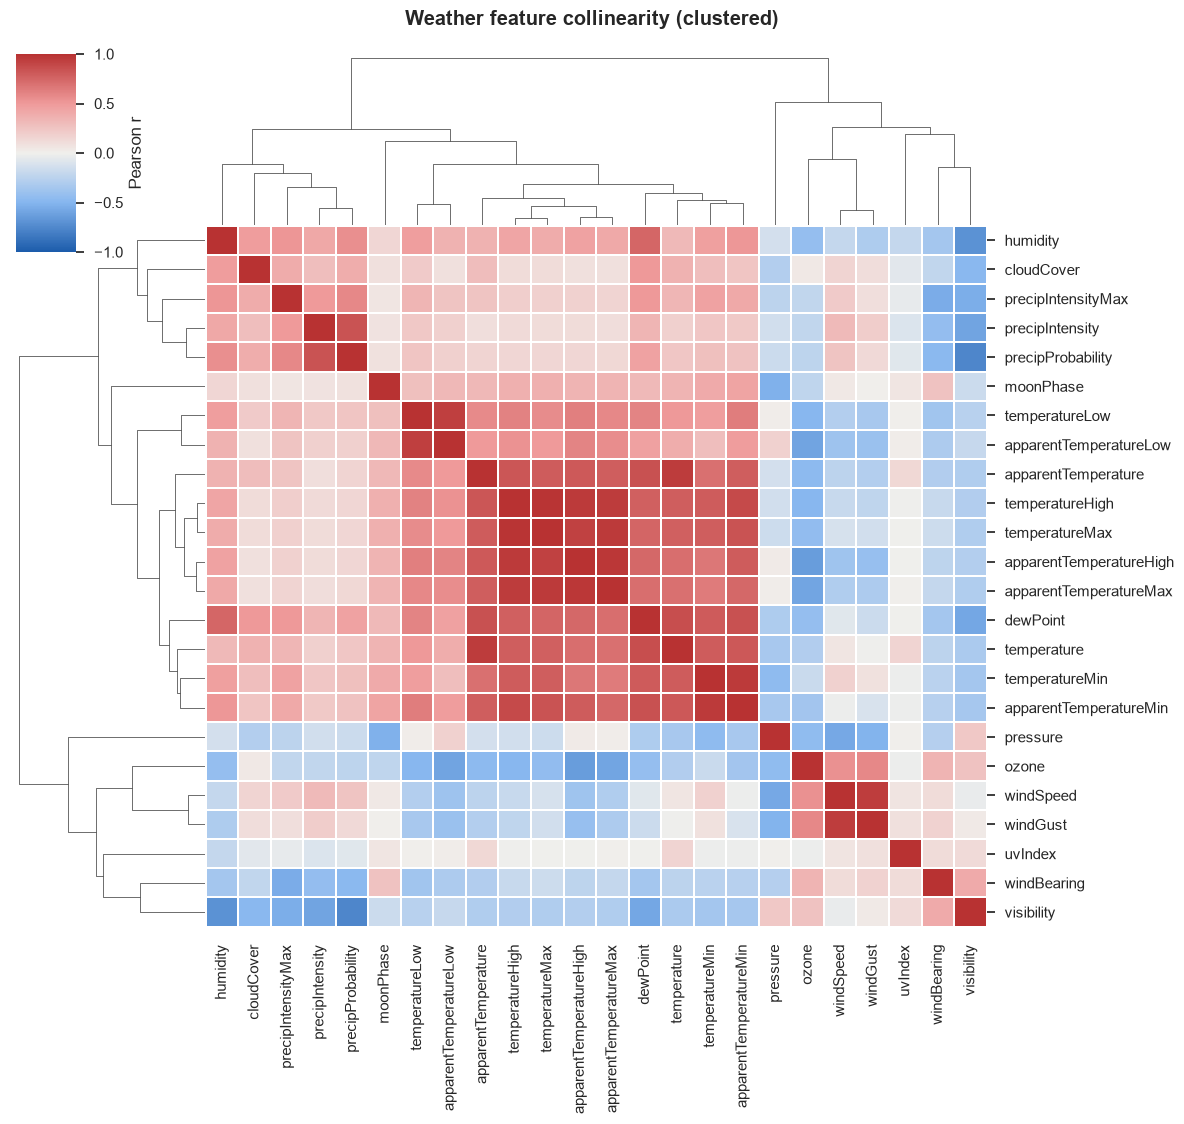

10 weather pairs with |r| > 0.9 (redundant information):
[('temperature', 'apparentTemperature', np.float64(0.946)), ('temperatureHigh', 'apparentTemperatureHigh', np.float64(0.959)), ('temperatureHigh', 'temperatureMax', np.float64(0.986)), ('temperatureHigh', 'apparentTemperatureMax', np.float64(0.951)), ('temperatureLow', 'apparentTemperatureLow', np.float64(0.934)), ('apparentTemperatureHigh', 'temperatureMax', np.float64(0.926)), ('apparentTemperatureHigh', 'apparentTemperatureMax', np.float64(0.974)), ('temperatureMin', 'apparentTemperatureMin', np.float64(0.954)), ('temperatureMax', 'apparentTemperatureMax', np.float64(0.956)), ('windSpeed', 'windGust', np.float64(0.938))]



R² of the 3-parameter tariff formula alone (class base + class rate x distance) x surge: 0.9585


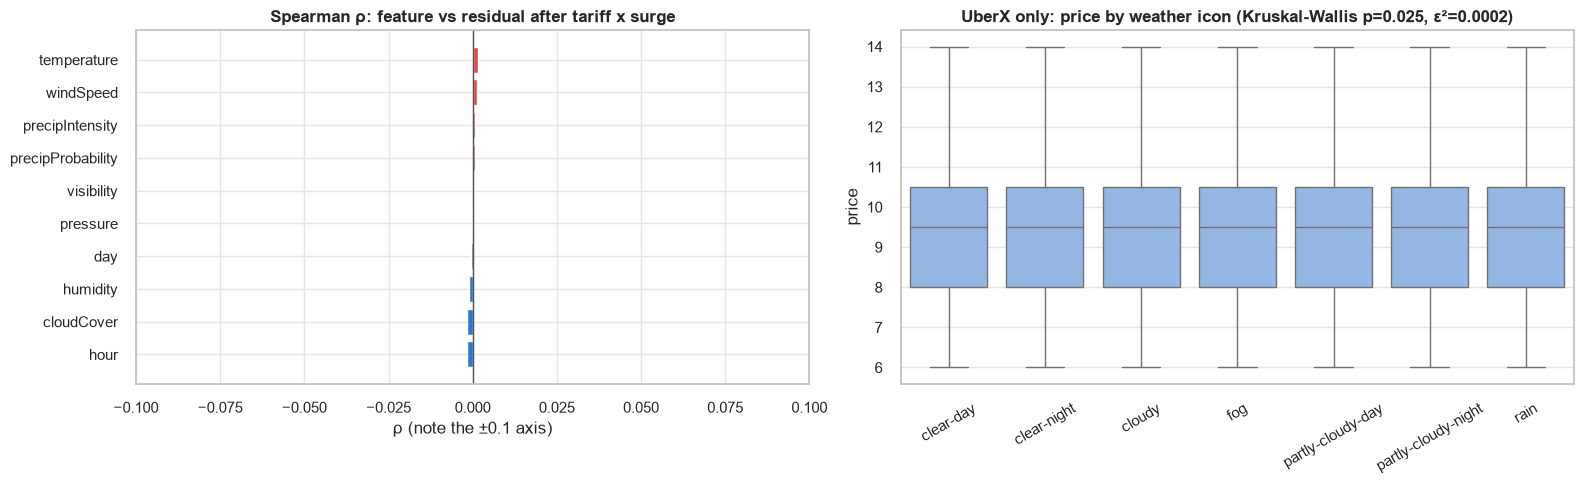

Columns kept for modelling: 25 | memory: 367 MB


In [15]:
weather_all = ['temperature', 'apparentTemperature', 'temperatureHigh', 'temperatureLow', 'apparentTemperatureHigh',
               'apparentTemperatureLow', 'temperatureMin', 'temperatureMax', 'apparentTemperatureMin', 'apparentTemperatureMax',
               'dewPoint', 'humidity', 'pressure', 'windSpeed', 'windGust', 'windBearing', 'cloudCover', 'uvIndex',
               'visibility', 'ozone', 'moonPhase', 'precipIntensity', 'precipIntensityMax', 'precipProbability']
weather_all = [c for c in weather_all if c in df.columns]
wcorr = df[weather_all].corr()
cg = sns.clustermap(wcorr, cmap=DIV, vmin=-1, vmax=1, figsize=(12, 11), linewidths=0.3, cbar_kws={'label': 'Pearson r'})
cg.fig.suptitle("Weather feature collinearity (clustered)", y=1.02, fontweight='bold'); plt.show()

hi = [(a, b, round(wcorr.loc[a, b], 3)) for i, a in enumerate(weather_all) for b in weather_all[i + 1:] if abs(wcorr.loc[a, b]) > 0.9]
print(f"{len(hi)} weather pairs with |r| > 0.9 (redundant information):"); print(hi)

# Residual vs class tariff x surge
expected = (df['name'].map(TARIFF['base_fare_$']) + df['name'].map(TARIFF['per_mile_$']) * df['distance']) * df['surge_multiplier']
df['tariff_resid'] = df['price'] - expected
r2_formula = 1 - (df['tariff_resid'] ** 2).sum() / ((df['price'] - df['price'].mean()) ** 2).sum()
print(f"\nR² of the 3-parameter tariff formula alone (class base + class rate x distance) x surge: {r2_formula:.4f}")

probe = ['temperature', 'humidity', 'windSpeed', 'precipIntensity', 'precipProbability', 'cloudCover', 'visibility', 'pressure', 'hour', 'day']
rho = pd.Series({c: stats.spearmanr(df[c], df['tariff_resid'])[0] for c in probe}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(rho.index, rho.values, color=[('#e34948' if v > 0 else ONE) for v in rho.values])
axes[0].axvline(0, color='#52514e', lw=1); axes[0].set_xlim(-0.1, 0.1)
axes[0].set_title("Spearman ρ: feature vs residual after tariff x surge"); axes[0].set_xlabel("ρ (note the ±0.1 axis)")

uberx = df[df['name'] == 'UberX'].copy(); uberx['icon_c'] = uberx['icon'].str.strip()
groups = [g['price'].values for _, g in uberx.groupby('icon_c')]
kw = stats.kruskal(*groups)
eta2 = (kw.statistic - len(groups) + 1) / (len(uberx) - len(groups))
sns.boxplot(data=uberx, x='icon_c', y='price', color='#86b6ef', showfliers=False, ax=axes[1],
            order=uberx.groupby('icon_c')['price'].median().sort_values().index)
axes[1].set_title(f"UberX only: price by weather icon (Kruskal-Wallis p={kw.pvalue:.2g}, ε²={eta2:.4f})")
axes[1].tick_params(axis='x', rotation=30); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

# --- Memory housekeeping: EDA is done, drop raw columns the modelling stages never use ---
import gc
keep = {'datetime', 'price', 'distance', 'surge_multiplier', 'hour', 'day', 'month', 'cab_type', 'name', 'source', 'destination',
        'temperature', 'apparentTemperature', 'humidity', 'windSpeed', 'windGust', 'visibility', 'precipIntensity',
        'precipProbability', 'pressure', 'cloudCover', 'uvIndex', 'dewPoint', 'short_summary', 'icon'}
df = df[[c for c in df.columns if c in keep]].copy()
del uberx, lyft, base_rides, cmp, std, samp, wcorr, expected
gc.collect()
print(f"Columns kept for modelling: {df.shape[1]} | memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")


## ⚙️ Cell 8 – Feature Engineering
Derive domain features: temporal indicators (`day_of_week`, `is_weekend`, `is_peak_hour`, `is_night`), `price_per_mile`, binned `temp_category`, and fitted `LabelEncoder` mappings.

In [16]:
# (price NaNs already dropped in Cell 4)

# Time features (from datetime column)
df['datetime'] = pd.to_datetime(df['datetime'])
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)
df['is_peak_hour'] = df['hour'].apply(lambda x: 1 if x in [7,8,9,16,17,18,19] else 0)
df['is_night'] = df['hour'].apply(lambda x: 1 if x < 6 or x >= 22 else 0)

# Price per mile
df['price_per_mile'] = df['price'] / (df['distance'] + 1e-5)

# Clean string whitespaces in categoricals
df['icon'] = df['icon'].astype(str).str.strip()
df['short_summary'] = df['short_summary'].astype(str).str.strip()

# Temperature categories
df['temp_category'] = pd.cut(df['temperature'], bins=[-np.inf, 32, 50, 65, 80, np.inf],
                              labels=['freezing','cold','mild','warm','hot'])

# Encode categoricals and retain fitted encoders dictionary for production
le_dict = {}
cat_cols = ['cab_type', 'name', 'source', 'destination', 'short_summary', 'icon', 'temp_category']
for col in cat_cols:
    le = LabelEncoder()
    df[col + '_enc'] = le.fit_transform(df[col].astype(str))
    le_dict[col] = le

print("✅ Feature engineering complete!")
print(f"Engineered Dataset Shape: {df.shape}")
display(df[['hour', 'day_of_week', 'is_weekend', 'is_peak_hour', 'is_night', 'price_per_mile', 'temp_category', 'cab_type_enc', 'name_enc']].head())

✅ Feature engineering complete!
Engineered Dataset Shape: (637976, 38)


,hour,day_of_week,is_weekend,is_peak_hour,is_night,price_per_mile,temp_category,cab_type_enc,name_enc
0,9,6,1,1,0,11.363378,cold,0,7
1,2,1,0,0,1,24.999432,cold,0,2
2,1,2,0,0,1,15.908729,cold,0,5
3,4,4,0,0,1,59.089566,cold,0,4
4,3,3,0,0,1,20.454081,cold,0,6


## 🔗 Cell 8b – Mutual Information: Which Features Carry Signal? *(new)*
Mutual information captures non-linear dependence. Computed on a 60k sample with categoricals flagged as discrete.

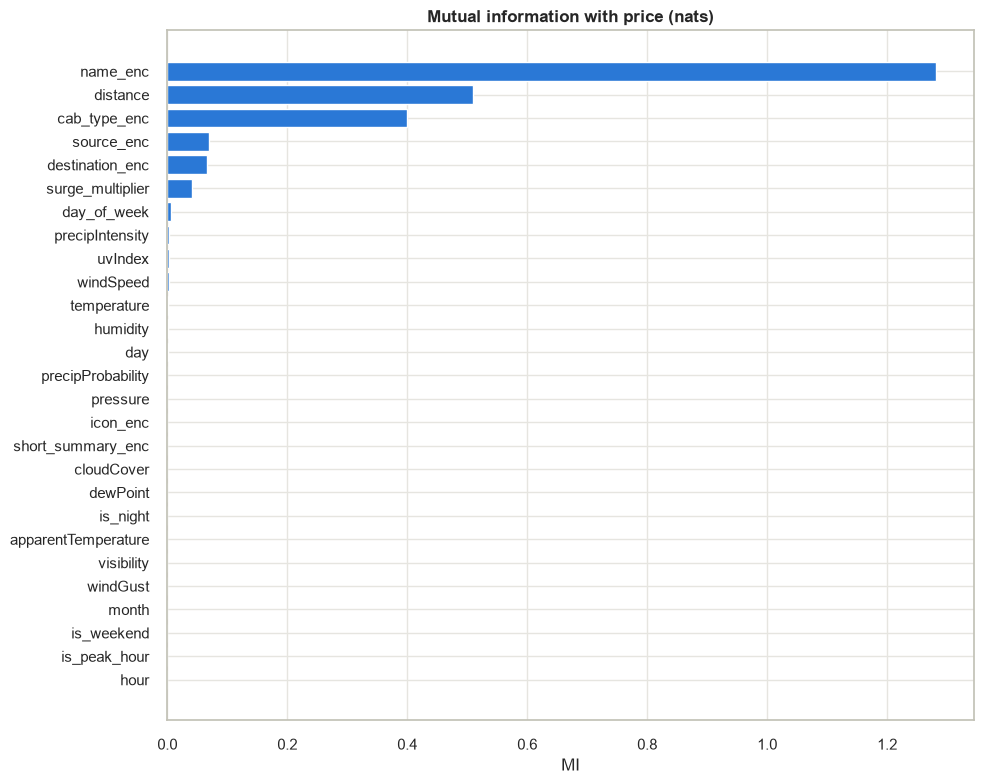

In [17]:
MI_FEATURES = ['distance', 'surge_multiplier', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'is_peak_hour', 'is_night',
               'temperature', 'apparentTemperature', 'humidity', 'windSpeed', 'windGust', 'visibility', 'precipIntensity',
               'precipProbability', 'pressure', 'cloudCover', 'uvIndex', 'dewPoint',
               'cab_type_enc', 'name_enc', 'source_enc', 'destination_enc', 'short_summary_enc', 'icon_enc']
mi_s = df.sample(60000, random_state=42)
discrete = [f.endswith('_enc') or f in ('hour', 'day', 'month', 'day_of_week', 'is_weekend', 'is_peak_hour', 'is_night', 'uvIndex')
            for f in MI_FEATURES]
mi = pd.Series(mutual_info_regression(mi_s[MI_FEATURES], mi_s['price'], discrete_features=discrete, random_state=42),
               index=MI_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(mi.index, mi.values, color=ONE)
ax.set_title("Mutual information with price (nats)"); ax.set_xlabel("MI")
plt.tight_layout(); plt.show()


## 🎯 Cell 9 – Feature Selection & Train/Test Split
Isolate 27 predictive features, split into 80% training and 20% testing sets, and apply `StandardScaler` normalization.

In [18]:
FEATURES = [
    'distance', 'surge_multiplier', 'hour', 'day', 'month',
    'day_of_week', 'is_weekend', 'is_peak_hour', 'is_night',
    'temperature', 'apparentTemperature', 'humidity', 'windSpeed',
    'windGust', 'visibility', 'precipIntensity', 'precipProbability',
    'pressure', 'cloudCover', 'uvIndex', 'dewPoint',
    'cab_type_enc', 'name_enc', 'source_enc', 'destination_enc',
    'short_summary_enc', 'icon_enc'
]

TARGET = 'price'

# Ensure day and month exist numerically
if 'day' not in df.columns:
    df['day'] = df['datetime'].dt.day
if 'month' not in df.columns:
    df['month'] = df['datetime'].dt.month

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")
print(f"Predictive features count: {len(FEATURES)}")

Training set: (510380, 27)
Test set:     (127596, 27)
Predictive features count: 27


## 🧱 Cell 9b – Naive & Formula Baselines *(new)*
A model is only impressive relative to a baseline. Two baselines fitted on the training set only:
1. **Class median** – predict the median price of the ride's service class.
2. **Tariff formula** – `(base_class + rate_class × distance) × surge`, coefficients fitted per class on training rides.

In [19]:
def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred), 'MAPE_%': np.mean(np.abs((y_true - y_pred) / y_true)) * 100}

train_df, test_df = df.loc[X_train.index], df.loc[X_test.index]
baseline_results = {}

class_median = train_df.groupby('name')['price'].median()
pred_med = test_df['name'].map(class_median).values
baseline_results['Baseline: class median'] = {**evaluate(y_test, pred_med), 'y_pred': pred_med}

tr_base = train_df[train_df['surge_multiplier'] == 1]
coef = {n: stats.linregress(g['distance'], g['price'])[:2] for n, g in tr_base.groupby('name')}
slope_s = test_df['name'].map({k: v[0] for k, v in coef.items()}); icpt_s = test_df['name'].map({k: v[1] for k, v in coef.items()})
pred_tar = ((icpt_s + slope_s * test_df['distance']) * test_df['surge_multiplier']).values
baseline_results['Baseline: tariff formula'] = {**evaluate(y_test, pred_tar), 'y_pred': pred_tar}

display(pd.DataFrame({k: {m: round(v[m], 4) for m in ['MAE', 'RMSE', 'R2', 'MAPE_%']} for k, v in baseline_results.items()}).T)


,MAE,RMSE,R2,MAPE_%
Baseline: class median,3.0284,4.5882,0.7585,19.7381
Baseline: tariff formula,1.3036,1.8883,0.9591,9.3980


## 📏 Cell 10 – Model Training: Linear Regression
Train an Ordinary Least Squares (OLS) baseline model to measure fundamental linear distance and surge elasticity.

In [20]:
# Model Training 1: Linear Regression
results = {}

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

results['Linear Regression'] = {
    'model': lr,
    'MAE': mae_lr,
    'RMSE': rmse_lr,
    'R2': r2_lr,
    'y_pred': y_pred_lr
}

print("=== Linear Regression Evaluation ===")
print(f"MAE:  ${mae_lr:.3f}")
print(f"RMSE: ${rmse_lr:.3f}")
print(f"R²:   {r2_lr:.4f}")

=== Linear Regression Evaluation ===
MAE:  $5.157
RMSE: $6.490
R²:   0.5169


## 📏 Cell 10b – Linear Regression Done Right: One-Hot + Interactions *(new)*
Label-encoding `name` (UberPool=0 … WAV=12) and feeding it to OLS assumes service classes lie on a line - they don't. The fair linear baseline one-hot encodes the class and lets each class have its own intercept, distance slope and surge interaction.

In [21]:
NAMES = sorted(df['name'].unique()); LOCS = sorted(df['source'].unique())
OHE_COLS = ['name', 'source', 'destination', 'distance', 'surge_multiplier', 'is_peak_hour', 'is_weekend']

def ohe_design(frame):
    d = frame['distance'].to_numpy(np.float32)[:, None]
    s = frame['surge_multiplier'].to_numpy(np.float32)[:, None]
    N = (frame['name'].to_numpy()[:, None] == np.array(NAMES)[None, :]).astype(np.float32)
    S = (frame['source'].to_numpy()[:, None] == np.array(LOCS)[None, 1:]).astype(np.float32)
    D = (frame['destination'].to_numpy()[:, None] == np.array(LOCS)[None, 1:]).astype(np.float32)
    extra = frame[['is_peak_hour', 'is_weekend']].to_numpy(np.float32)
    return np.hstack([N, N * d, N * s, N * d * s, S, D, extra])

lr_ohe = make_pipeline(FunctionTransformer(ohe_design), LinearRegression(fit_intercept=False))
t0 = time.time()
lr_ohe.fit(train_df[OHE_COLS], y_train)
y_pred_lr_ohe = lr_ohe.predict(test_df[OHE_COLS])
alt_results = {'Linear Regression (one-hot + interactions)': {**evaluate(y_test, y_pred_lr_ohe), 'y_pred': y_pred_lr_ohe}}
m = alt_results['Linear Regression (one-hot + interactions)']
print(f"=== One-hot OLS ({time.time() - t0:.1f}s) ===\nMAE: ${m['MAE']:.3f} | RMSE: ${m['RMSE']:.3f} | R²: {m['R2']:.4f}")


=== One-hot OLS (7.7s) ===
MAE: $1.271 | RMSE: $1.854 | R²: 0.9606


## 🌲 Cell 11 – Model Training: Random Forest
Train a non-linear ensemble of 100 bagged decision trees to capture vehicle class and spatial threshold interactions.

In [22]:
# Model Training 2: Random Forest Regressor
# Using optimal subsampling on large data to ensure high accuracy without memory bottlenecks
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    max_samples=0.4 if len(X_train) > 100000 else None
)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

results['Random Forest'] = {
    'model': rf,
    'MAE': mae_rf,
    'RMSE': rmse_rf,
    'R2': r2_rf,
    'y_pred': y_pred_rf
}

print("=== Random Forest Evaluation ===")
print(f"MAE:  ${mae_rf:.3f}")
print(f"RMSE: ${rmse_rf:.3f}")
print(f"R²:   {r2_rf:.4f}")

=== Random Forest Evaluation ===
MAE:  $1.114
RMSE: $1.722
R²:   0.9660


## 🚀 Cell 12 – Model Training: Gradient Boosting
Train a sequential Gradient Boosting ensemble (`learning_rate=0.1`, `max_depth=5`) optimizing pseudo-residual gradients.

In [23]:
# Model Training 3: Gradient Boosting Regressor
gb_sample_size = min(60000, len(X_train_scaled))
gb_idx = np.random.RandomState(42).choice(len(X_train_scaled), gb_sample_size, replace=False)

gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
gb.fit(X_train_scaled[gb_idx], y_train.iloc[gb_idx])

y_pred_gb = gb.predict(X_test_scaled)
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

results['Gradient Boosting'] = {
    'model': gb,
    'MAE': mae_gb,
    'RMSE': rmse_gb,
    'R2': r2_gb,
    'y_pred': y_pred_gb
}

print("=== Gradient Boosting Evaluation ===")
print(f"MAE:  ${mae_gb:.3f}")
print(f"RMSE: ${rmse_gb:.3f}")
print(f"R²:   {r2_gb:.4f}")

=== Gradient Boosting Evaluation ===
MAE:  $1.141
RMSE: $1.724
R²:   0.9659


## ⚡ Cell 13 – Model Training: XGBoost
Train regularized Extreme Gradient Boosted Trees (`n_estimators=200`, `max_depth=6`, `learning_rate=0.1`) and select champion architecture.

In [24]:
# Model Training 4: XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)
xgb_model.fit(X_train_scaled, y_train)

y_pred_xgb = xgb_model.predict(X_test_scaled)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

results['XGBoost'] = {
    'model': xgb_model,
    'MAE': mae_xgb,
    'RMSE': rmse_xgb,
    'R2': r2_xgb,
    'y_pred': y_pred_xgb
}

print("=== XGBoost Evaluation ===")
print(f"MAE:  ${mae_xgb:.3f}")
print(f"RMSE: ${rmse_xgb:.3f}")
print(f"R²:   {r2_xgb:.4f}")

# Select champion model
best_model_name = max(results.keys(), key=lambda m: results[m]['R2'])
best_model = results[best_model_name]['model']
print(f"🏆 Champion Model Selected: {best_model_name} (R² = {results[best_model_name]['R2']:.4f})")

=== XGBoost Evaluation ===
MAE:  $1.084
RMSE: $1.650
R²:   0.9688
🏆 Champion Model Selected: XGBoost (R² = 0.9688)


## 🔁 Cell 13b – Honest 5-Fold Cross-Validation for *Every* Model *(new)*
The original saved `CV_R2 = R2 - 0.002` for Linear Regression and Gradient Boosting instead of computing it. Here all models are cross-validated on the **same** 25k-row training sample with the same folds.

Linear Regression                             R² = 0.5149 ± 0.0082   (0.2s)
Linear Regression (one-hot + interactions)    R² = 0.9586 ± 0.0025   (1.7s)
Random Forest                                 R² = 0.9565 ± 0.0026   (49.7s)
Gradient Boosting                             R² = 0.9621 ± 0.0024   (66.8s)
XGBoost                                       R² = 0.9618 ± 0.0020   (4.8s)


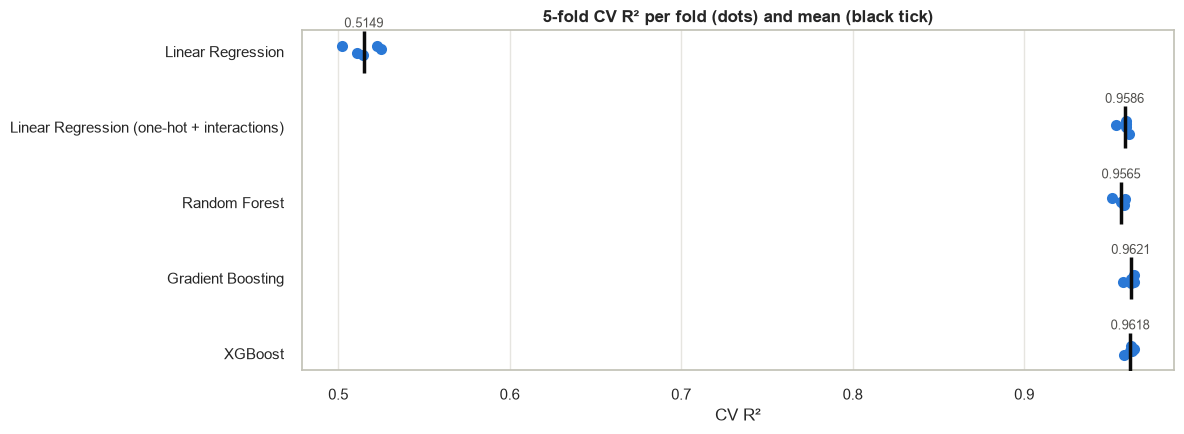

In [25]:
cv_n = min(25000, len(X_train_scaled))
cv_idx = np.random.RandomState(42).choice(len(X_train_scaled), cv_n, replace=False)
X_cv, y_cv = X_train_scaled[cv_idx], y_train.iloc[cv_idx]
folds = KFold(n_splits=5, shuffle=True, random_state=42)

cv_specs = {
    'Linear Regression': (LinearRegression(), X_cv),
    'Linear Regression (one-hot + interactions)': (make_pipeline(FunctionTransformer(ohe_design), LinearRegression(fit_intercept=False)),
                                                   train_df[OHE_COLS].iloc[cv_idx]),
    'Random Forest': (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), X_cv),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42), X_cv),
    'XGBoost': (xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1, tree_method='hist'), X_cv),
}
cv_results = {}
for name, (est, Xc) in cv_specs.items():
    t0 = time.time()
    cv_results[name] = cross_val_score(est, Xc, y_cv, cv=folds, scoring='r2', n_jobs=1)
    print(f"{name:45s} R² = {cv_results[name].mean():.4f} ± {cv_results[name].std():.4f}   ({time.time() - t0:.1f}s)")

# keep the variable names used by the original save cell
cv_scores_xgb, cv_scores_rf = cv_results['XGBoost'], cv_results['Random Forest']

cv_long = pd.DataFrame([(k, s) for k, v in cv_results.items() for s in v], columns=['Model', 'CV R²'])
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.stripplot(data=cv_long, y='Model', x='CV R²', color=ONE, size=8, ax=ax)
means = cv_long.groupby('Model', sort=False)['CV R²'].mean()
ax.scatter(means.values, range(len(means)), marker='|', s=900, linewidths=2.5, color='#0b0b0b', zorder=5)
for i, v in enumerate(means.values):
    ax.text(v, i - 0.32, f"{v:.4f}", ha='center', fontsize=9, color='#52514e')
ax.set_title("5-fold CV R² per fold (dots) and mean (black tick)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


## 📊 Cell 14 – Model Comparison & Evaluation
Tabulate comparative metrics across models (MAE, RMSE, $R^2$), plot metric bars, and generate Actual vs. Predicted and Residual scatter distributions.

=== Model Comparison Matrix ===


,Model,MAE ($),RMSE ($),R² Score
3,XGBoost,1.084,1.650,0.9688
1,Random Forest,1.114,1.722,0.9660
2,Gradient Boosting,1.141,1.724,0.9659
0,Linear Regression,5.157,6.490,0.5169


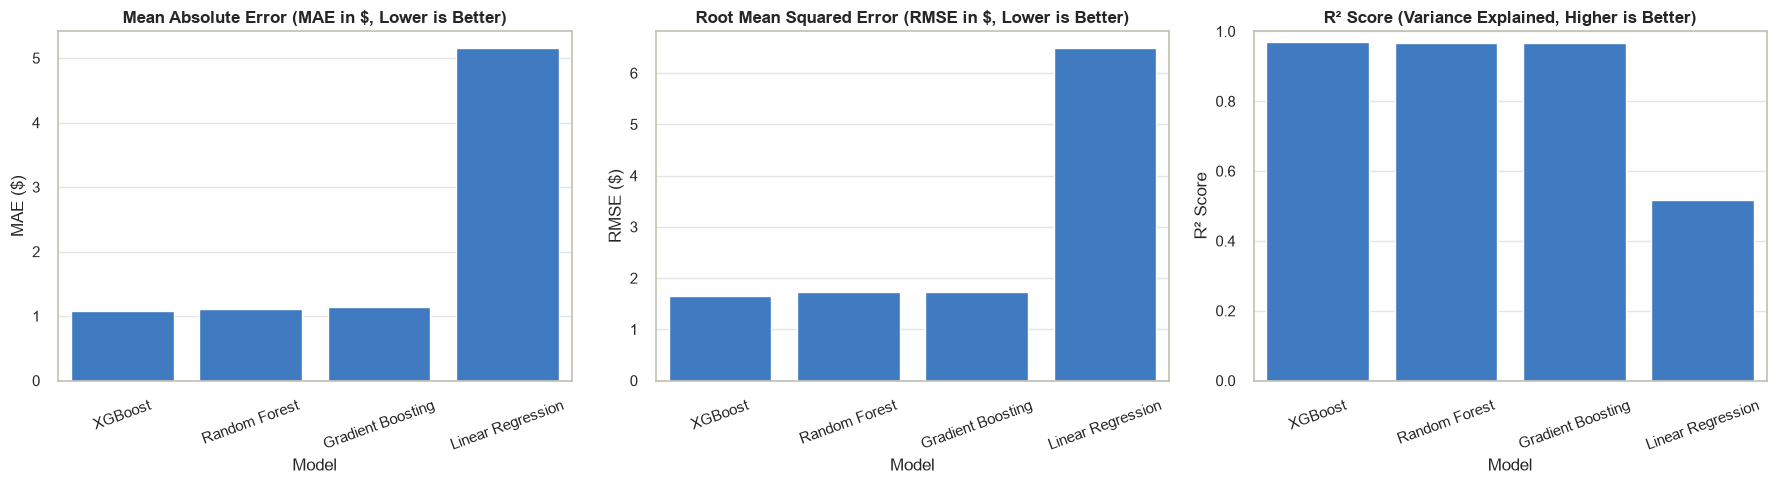

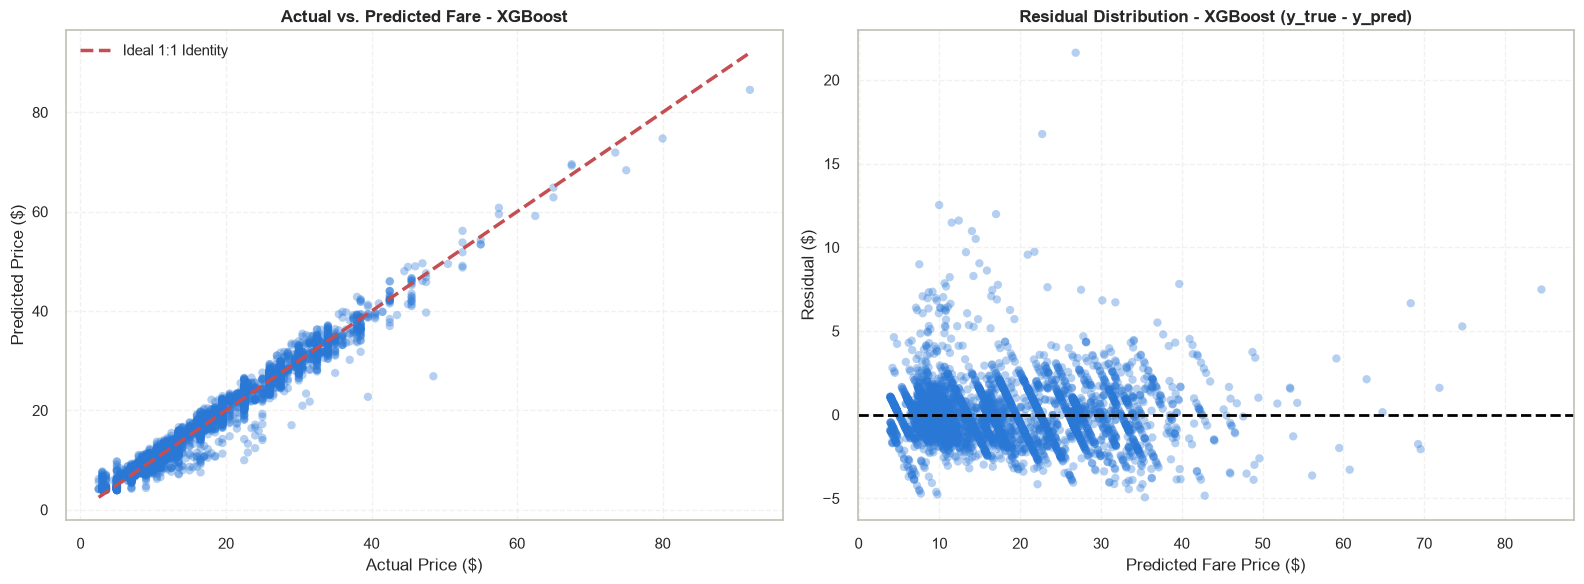

In [26]:
# Model Comparison & Evaluation
metrics_summary = []
for name, data in results.items():
    metrics_summary.append({
        'Model': name,
        'MAE ($)': round(data['MAE'], 3),
        'RMSE ($)': round(data['RMSE'], 3),
        'R² Score': round(data['R2'], 4)
    })

comparison_df = pd.DataFrame(metrics_summary).sort_values(by='R² Score', ascending=False)
print("=== Model Comparison Matrix ===")
display(comparison_df)

# Visual Comparison Bars
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE
sns.barplot(data=comparison_df, x='Model', y='MAE ($)', color=ONE, ax=axes[0])
axes[0].set_title("Mean Absolute Error (MAE in $, Lower is Better)", fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=20)

# RMSE
sns.barplot(data=comparison_df, x='Model', y='RMSE ($)', color=ONE, ax=axes[1])
axes[1].set_title("Root Mean Squared Error (RMSE in $, Lower is Better)", fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=20)

# R2
sns.barplot(data=comparison_df, x='Model', y='R² Score', color=ONE, ax=axes[2])
axes[2].set_title("R² Score (Variance Explained, Higher is Better)", fontsize=12, fontweight='bold')
axes[2].set_ylim(0, 1.0)
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# Actual vs Predicted & Residuals Diagnostics for Champion Model
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

best_y_pred = results[best_model_name]['y_pred']
residuals = y_test - best_y_pred

# Subsample points for crisp scatter visualization
diag_sample = np.random.RandomState(42).choice(len(y_test), min(5000, len(y_test)), replace=False)
y_test_sub = y_test.iloc[diag_sample]
pred_sub = best_y_pred[diag_sample]
res_sub = residuals.iloc[diag_sample]

# Actual vs Predicted
axes[0].scatter(y_test_sub, pred_sub, alpha=0.35, color=ONE, edgecolors='none')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2.5, label='Ideal 1:1 Identity')
axes[0].set_title(f"Actual vs. Predicted Fare - {best_model_name}", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Residuals Plot
axes[1].scatter(pred_sub, res_sub, alpha=0.35, color=ONE, edgecolors='none')
axes[1].axhline(0, color='black', linestyle='--', lw=2)
axes[1].set_title(f"Residual Distribution - {best_model_name} (y_true - y_pred)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Predicted Fare Price ($)")
axes[1].set_ylabel("Residual ($)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 🏁 Cell 14b – Full Leaderboard Incl. Baselines, MAPE & CV *(new)*

,Model,Type,MAE ($),RMSE ($),R²,MAPE (%),CV R² (mean),CV R² (std)
0,XGBoost,Model (app-compatible),1.084,1.650,0.9688,8.05,0.9618,0.0020
1,Random Forest,Model (app-compatible),1.114,1.722,0.9660,8.28,0.9565,0.0026
2,Gradient Boosting,Model (app-compatible),1.141,1.724,0.9659,8.46,0.9621,0.0024
3,Linear Regression (one-hot + interactions),Alt. model,1.271,1.854,0.9606,9.31,0.9586,0.0025
4,Baseline: tariff formula,Baseline,1.304,1.888,0.9591,9.40,-,-
5,Baseline: class median,Baseline,3.028,4.588,0.7585,19.74,-,-
6,Linear Regression,Model (app-compatible),5.157,6.490,0.5169,39.37,0.5149,0.0082


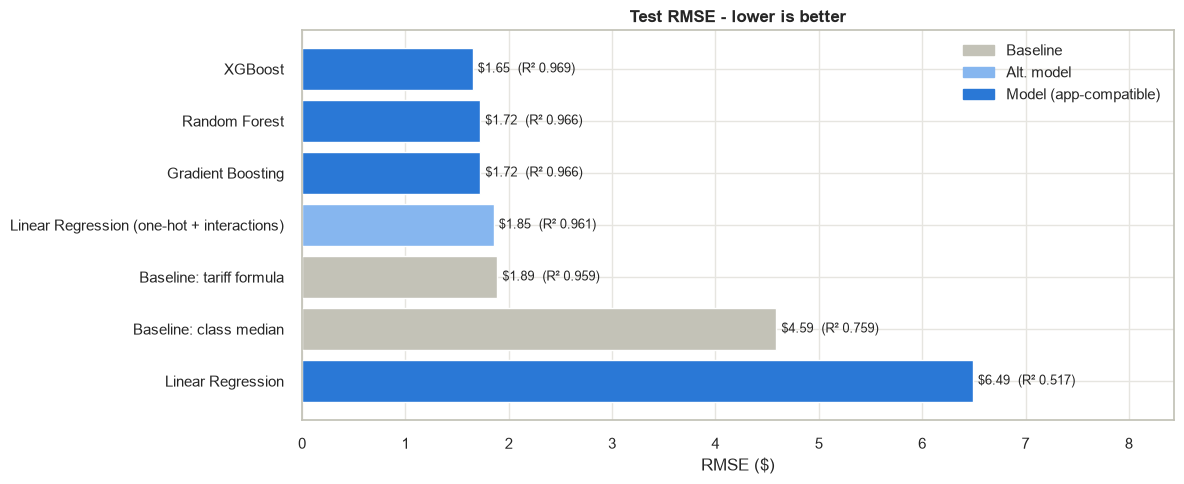

In [27]:
board = []
for group, dct in [('Baseline', baseline_results), ('Alt. model', alt_results), ('Model (app-compatible)', results)]:
    for name, v in dct.items():
        e = evaluate(y_test, v['y_pred'])
        cvs = cv_results.get(name)
        board.append({'Model': name, 'Type': group, 'MAE ($)': e['MAE'], 'RMSE ($)': e['RMSE'], 'R²': e['R2'],
                      'MAPE (%)': e['MAPE_%'], 'CV R² (mean)': None if cvs is None else cvs.mean(),
                      'CV R² (std)': None if cvs is None else cvs.std()})
leaderboard = pd.DataFrame(board).sort_values('RMSE ($)').reset_index(drop=True)
display(leaderboard.style.format({'MAE ($)': '{:.3f}', 'RMSE ($)': '{:.3f}', 'R²': '{:.4f}', 'MAPE (%)': '{:.2f}',
                                  'CV R² (mean)': '{:.4f}', 'CV R² (std)': '{:.4f}'}, na_rep='-'))

fig, ax = plt.subplots(figsize=(12, 5))
lb = leaderboard.sort_values('RMSE ($)', ascending=False)
type_col = {'Baseline': '#c3c2b7', 'Alt. model': '#86b6ef', 'Model (app-compatible)': ONE}
ax.barh(lb['Model'], lb['RMSE ($)'], color=lb['Type'].map(type_col))
for i, (v, r2) in enumerate(zip(lb['RMSE ($)'], lb['R²'])):
    ax.text(v + 0.05, i, f"${v:.2f}  (R² {r2:.3f})", va='center', fontsize=9)
ax.set_title("Test RMSE - lower is better"); ax.set_xlabel("RMSE ($)"); ax.set_xlim(0, lb['RMSE ($)'].max() * 1.3)
ax.legend(handles=[Patch(color=c, label=k) for k, c in type_col.items()], loc='upper right')
plt.tight_layout(); plt.show()


## 🩺 Cell 14c – Error Diagnostics for the Champion *(new)*
Where does the model fail? Errors broken down by service class, distance band and surge level.

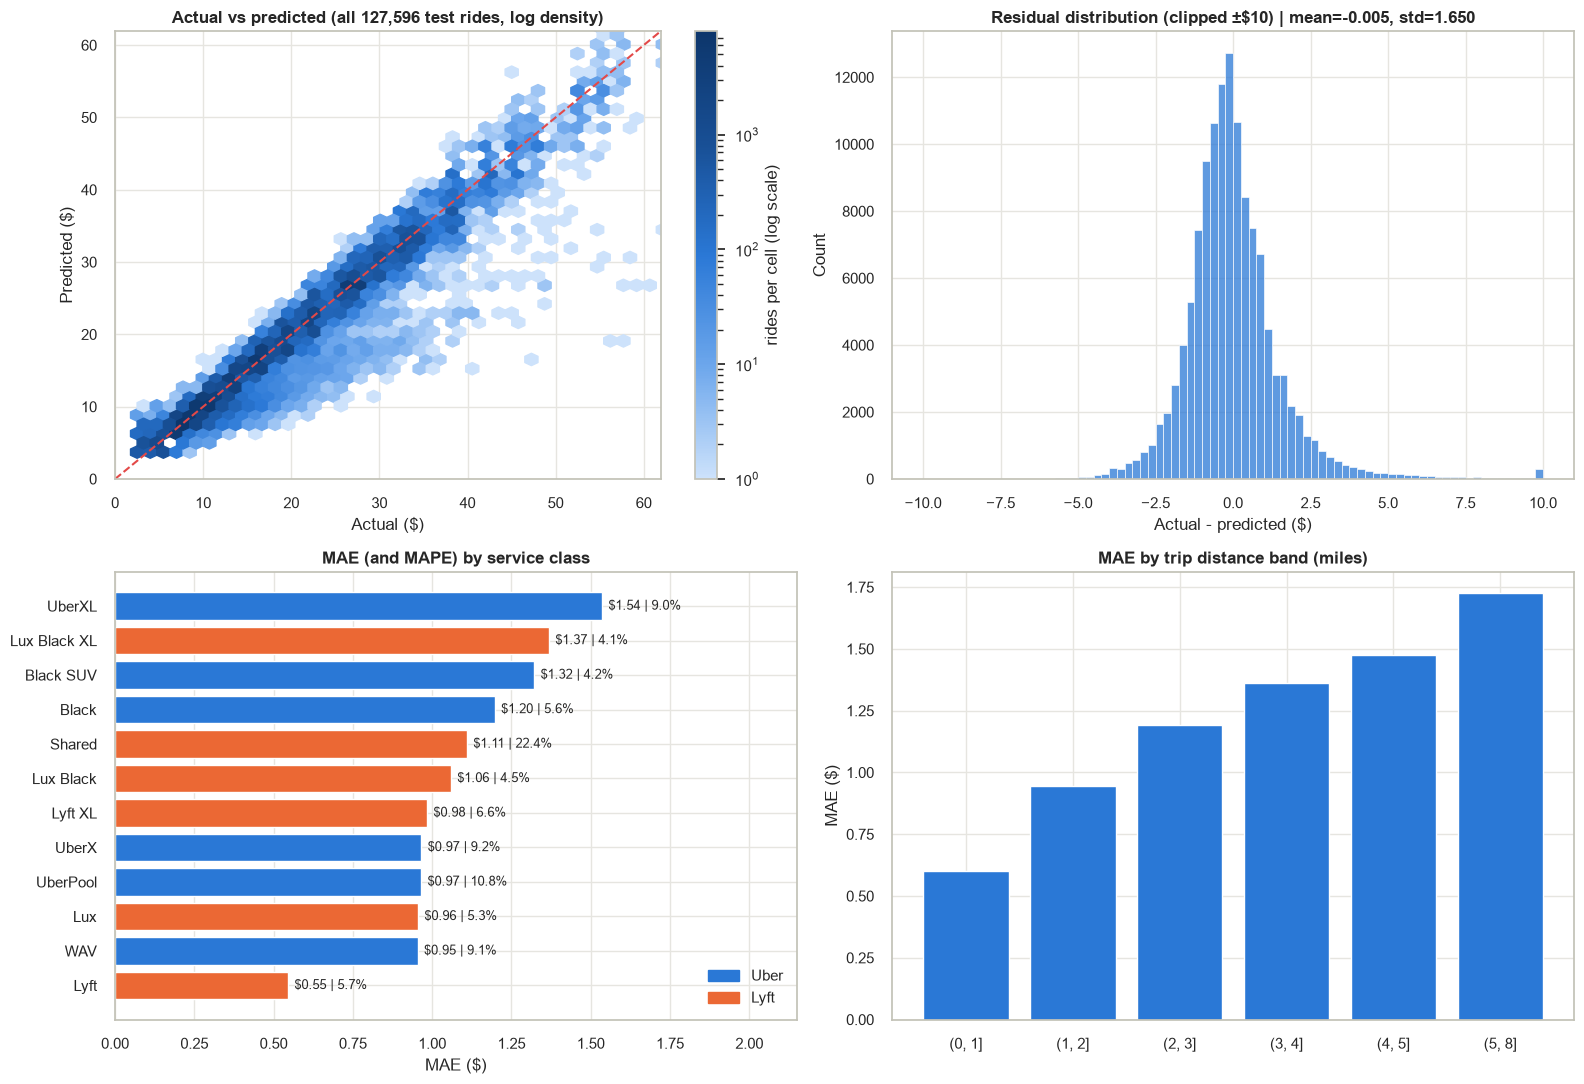

MAE by surge level:


,mean,count
surge_multiplier,,
1.00,1.070,123394
1.25,1.241,2200
1.50,1.548,1035
1.75,1.883,470
2.00,1.949,462
2.50,1.682,32
3.00,2.128,3


In [28]:
diag = test_df[['name', 'cab_type', 'distance', 'surge_multiplier']].copy()
diag['actual'] = y_test.values
diag['pred'] = results[best_model_name]['y_pred']
diag['resid'] = diag['actual'] - diag['pred']
diag['abs_err'] = diag['resid'].abs()
diag['ape'] = diag['abs_err'] / diag['actual'] * 100

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
hb = axes[0, 0].hexbin(diag['actual'], diag['pred'], gridsize=60, cmap=SEQ, mincnt=1, bins='log')
lim = [0, diag['actual'].quantile(0.999)]
axes[0, 0].plot(lim, lim, color='#e34948', lw=1.5, ls='--'); axes[0, 0].set_xlim(lim); axes[0, 0].set_ylim(lim)
axes[0, 0].set_title(f"Actual vs predicted (all {len(diag):,} test rides, log density)")
axes[0, 0].set_xlabel("Actual ($)"); axes[0, 0].set_ylabel("Predicted ($)"); fig.colorbar(hb, ax=axes[0, 0], label='rides per cell (log scale)')

sns.histplot(diag['resid'].clip(-10, 10), bins=80, color=ONE, ax=axes[0, 1])
axes[0, 1].set_title(f"Residual distribution (clipped ±$10) | mean={diag['resid'].mean():.3f}, std={diag['resid'].std():.3f}")
axes[0, 1].set_xlabel("Actual - predicted ($)")

per_class = diag.groupby(['name', 'cab_type']).agg(MAE=('abs_err', 'mean'), MAPE=('ape', 'mean')).reset_index().sort_values('MAE')
axes[1, 0].barh(per_class['name'], per_class['MAE'], color=per_class['cab_type'].map(PLATFORM))
for i, r in enumerate(per_class.itertuples()):
    axes[1, 0].text(r.MAE + 0.02, i, f"${r.MAE:.2f} | {r.MAPE:.1f}%", va='center', fontsize=9)
axes[1, 0].set_title("MAE (and MAPE) by service class"); axes[1, 0].set_xlabel("MAE ($)")
axes[1, 0].set_xlim(0, per_class['MAE'].max() * 1.4)
axes[1, 0].legend(handles=[Patch(color=c, label=k) for k, c in PLATFORM.items()], loc='lower right')

diag['dist_band'] = pd.cut(diag['distance'], [0, 1, 2, 3, 4, 5, 8])
band = diag.groupby('dist_band', observed=True)['abs_err'].mean()
axes[1, 1].bar(band.index.astype(str), band.values, color=ONE)
axes[1, 1].set_title("MAE by trip distance band (miles)"); axes[1, 1].set_ylabel("MAE ($)")
plt.tight_layout(); plt.show()

print("MAE by surge level:"); display(diag.groupby('surge_multiplier')['abs_err'].agg(['mean', 'count']).round(3))


## 💡 Cell 15 – Feature Importance
Extract and plot top-15 predictive feature importance rankings from tree ensembles (XGBoost and Random Forest).

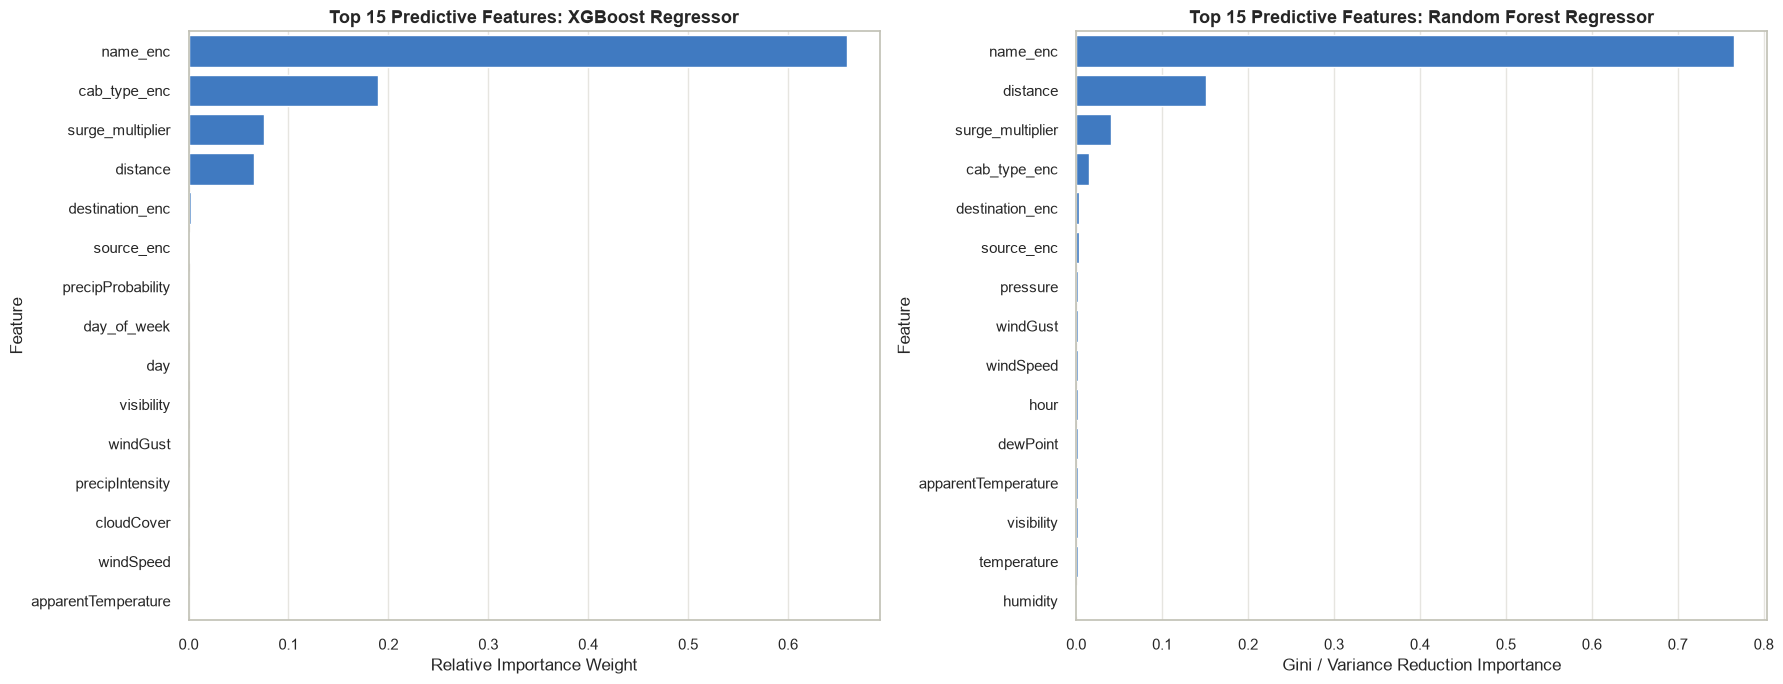

In [29]:
# Feature Importance Analysis
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. XGBoost Feature Importance
xgb_fi = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(15)

sns.barplot(data=xgb_fi, x='Importance', y='Feature', color=ONE, ax=axes[0])
axes[0].set_title("Top 15 Predictive Features: XGBoost Regressor", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Relative Importance Weight")

# 2. Random Forest Feature Importance
rf_fi = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False).head(15)

sns.barplot(data=rf_fi, x='Importance', y='Feature', color=ONE, ax=axes[1])
axes[1].set_title("Top 15 Predictive Features: Random Forest Regressor", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Gini / Variance Reduction Importance")

plt.tight_layout()
plt.show()

In [30]:
# Free the full-depth Random Forest (~1-2 GB in RAM) unless it is the champion
if best_model_name != 'Random Forest':
    results['Random Forest']['model'] = None
    del rf
gc.collect()


30289

## 🎲 Cell 15b – Permutation Importance & Feature-Group Ablation *(new)*
Impurity-based importances are biased toward high-cardinality features and split credit arbitrarily between correlated ones (e.g. the 8 temperature columns). Permutation importance measures the actual R² drop on held-out data; ablation retrains without whole feature groups.

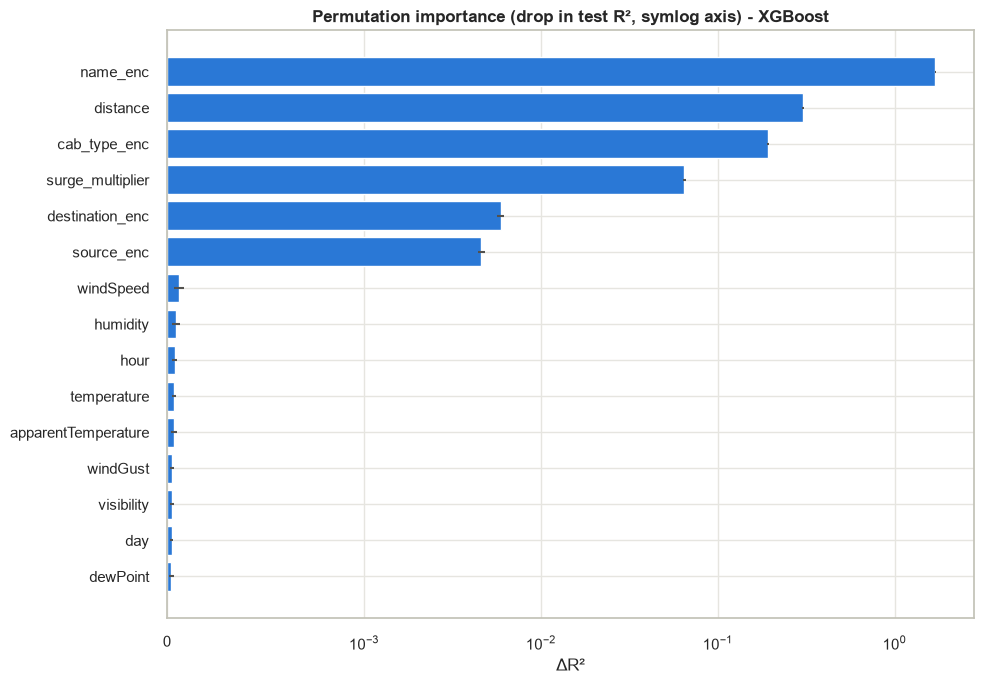

,Feature set,n_features,R²,RMSE ($),MAE ($)
0,All 27 features,27,0.9688,1.6504,1.0836
1,No weather (13 left),13,0.9690,1.6445,1.0802
2,No time,20,0.9687,1.6517,1.0852
3,No weather & no time (6 left),6,0.9691,1.6416,1.0767
4,Only distance + surge + name + cab_type,4,0.9653,1.7401,1.1445
5,Without name_enc,26,0.1810,8.4501,6.9114
6,Without distance,26,0.9585,1.9027,1.2548


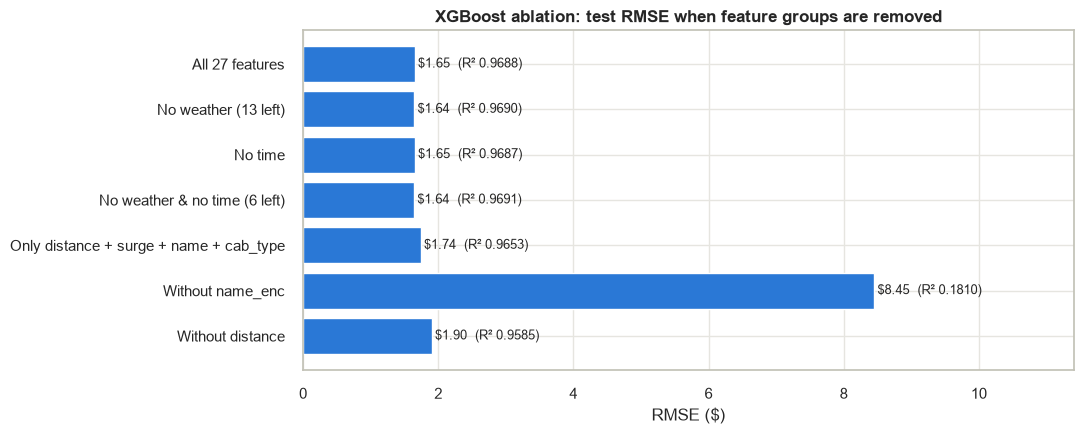

In [31]:
pi_idx = np.random.RandomState(0).choice(len(X_test_scaled), 20000, replace=False)
pi = permutation_importance(xgb_model, X_test_scaled[pi_idx], y_test.iloc[pi_idx], n_repeats=5, random_state=42, scoring='r2', n_jobs=1)
pi_df = pd.DataFrame({'Feature': FEATURES, 'mean': pi.importances_mean, 'std': pi.importances_std}).sort_values('mean').tail(15)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(pi_df['Feature'], pi_df['mean'], xerr=pi_df['std'], color=ONE, error_kw={'ecolor': '#52514e'})
ax.set_xscale('symlog', linthresh=1e-3)
ax.set_title("Permutation importance (drop in test R², symlog axis) - XGBoost"); ax.set_xlabel("ΔR²")
plt.tight_layout(); plt.show()

WEATHER_F = ['temperature', 'apparentTemperature', 'humidity', 'windSpeed', 'windGust', 'visibility', 'precipIntensity',
             'precipProbability', 'pressure', 'cloudCover', 'uvIndex', 'dewPoint', 'short_summary_enc', 'icon_enc']
TIME_F = ['hour', 'day', 'month', 'day_of_week', 'is_weekend', 'is_peak_hour', 'is_night']
groups = {
    'All 27 features': FEATURES,
    'No weather (13 left)': [f for f in FEATURES if f not in WEATHER_F],
    'No time': [f for f in FEATURES if f not in TIME_F],
    'No weather & no time (6 left)': [f for f in FEATURES if f not in WEATHER_F + TIME_F],
    'Only distance + surge + name + cab_type': ['distance', 'surge_multiplier', 'name_enc', 'cab_type_enc'],
    'Without name_enc': [f for f in FEATURES if f != 'name_enc'],
    'Without distance': [f for f in FEATURES if f != 'distance'],
}
abl = []
for label, feats in groups.items():
    m = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1, tree_method='hist')
    m.fit(X_train[feats], y_train)
    e = evaluate(y_test, m.predict(X_test[feats]))
    abl.append({'Feature set': label, 'n_features': len(feats), 'R²': e['R2'], 'RMSE ($)': e['RMSE'], 'MAE ($)': e['MAE']})
abl = pd.DataFrame(abl)
display(abl.round(4))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(abl['Feature set'][::-1], abl['RMSE ($)'][::-1], color=ONE)
for i, (v, r2) in enumerate(zip(abl['RMSE ($)'][::-1], abl['R²'][::-1])):
    ax.text(v + 0.05, i, f"${v:.2f}  (R² {r2:.4f})", va='center', fontsize=9)
ax.set_title("XGBoost ablation: test RMSE when feature groups are removed"); ax.set_xlabel("RMSE ($)")
ax.set_xlim(0, abl['RMSE ($)'].max() * 1.35)
plt.tight_layout(); plt.show()


## 📉 Cell 15c – Partial Dependence: How the Champion Responds *(new)*
Vary one input over a grid while holding each sampled ride's other features fixed, then average the prediction. Plotted per service class in original units.

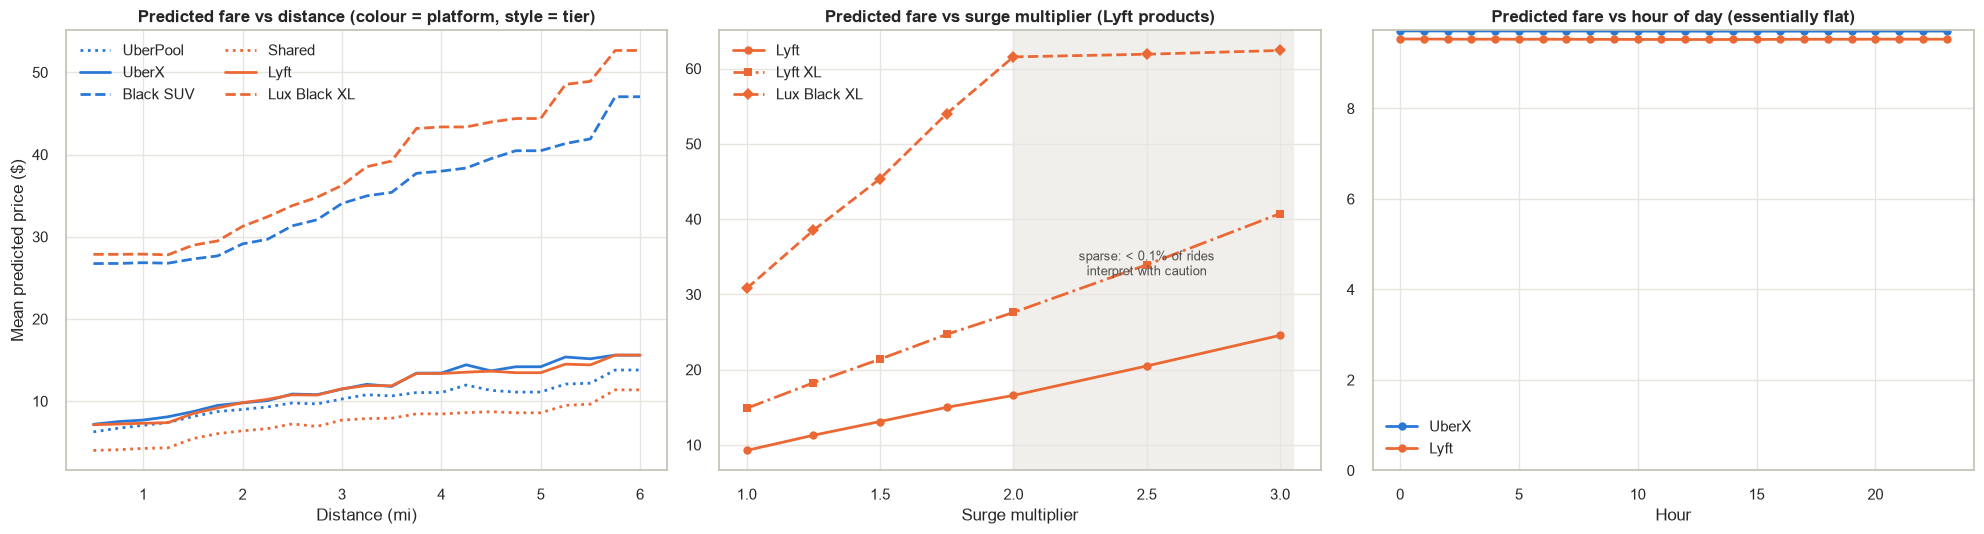

In [32]:
def pdp_curve(feature, grid, rows):
    out = []
    for v in grid:
        Xm = rows.copy(); Xm[feature] = v
        out.append(best_model.predict(scaler.transform(Xm.values)).mean())
    return np.array(out)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
# colour = platform (same as every other chart), line style = tier
showcase = [('UberPool', 'Uber', ':'), ('UberX', 'Uber', '-'), ('Black SUV', 'Uber', '--'),
            ('Shared', 'Lyft', ':'), ('Lyft', 'Lyft', '-'), ('Lux Black XL', 'Lyft', '--')]
dist_grid = np.linspace(0.5, 6, 23)
for name, cab, ls in showcase:
    rows = X_test[test_df['name'] == name].sample(400, random_state=42)
    axes[0].plot(dist_grid, pdp_curve('distance', dist_grid, rows), color=PLATFORM[cab], ls=ls, lw=2, label=name)
axes[0].set_title("Predicted fare vs distance (colour = platform, style = tier)")
axes[0].set_xlabel("Distance (mi)"); axes[0].set_ylabel("Mean predicted price ($)"); axes[0].legend(ncol=2)

# Shared never surges in the data, so it is excluded (its curve would be pure extrapolation)
surge_grid = sorted(df['surge_multiplier'].unique())
for name, ls, mk in [('Lyft', '-', 'o'), ('Lyft XL', '-.', 's'), ('Lux Black XL', '--', 'D')]:
    rows = X_test[test_df['name'] == name].sample(400, random_state=42)
    axes[1].plot(surge_grid, pdp_curve('surge_multiplier', surge_grid, rows), marker=mk, ls=ls, color=PLATFORM['Lyft'], lw=2, label=name)
axes[1].axvspan(2.0, 3.05, color='#f0efec', zorder=0)
axes[1].text(2.5, axes[1].get_ylim()[1] * 0.5, "sparse: < 0.1% of rides\ninterpret with caution", ha='center', fontsize=9, color='#52514e')
axes[1].set_title("Predicted fare vs surge multiplier (Lyft products)"); axes[1].set_xlabel("Surge multiplier"); axes[1].legend()

hour_grid = np.arange(24)
for k, name in enumerate(['UberX', 'Lyft']):
    rows = X_test[test_df['name'] == name].sample(400, random_state=42)
    rows = rows.assign(is_peak_hour=0, is_night=0)
    curve = []
    for h in hour_grid:
        Xm = rows.copy(); Xm['hour'] = h; Xm['is_peak_hour'] = int(h in [7, 8, 9, 16, 17, 18, 19]); Xm['is_night'] = int(h < 6 or h >= 22)
        curve.append(best_model.predict(scaler.transform(Xm.values)).mean())
    axes[2].plot(hour_grid, curve, marker='o', color=PLATFORM['Uber' if name == 'UberX' else 'Lyft'], lw=2, label=name)
axes[2].set_title("Predicted fare vs hour of day (essentially flat)"); axes[2].set_xlabel("Hour"); axes[2].legend()
axes[2].set_ylim(0, None)
plt.tight_layout(); plt.show()


## 🧠 Cell 17 – Pricing Recommendation Module *(fixed)*
Fixes the `scaler = scaler` bug (it raised `UnboundLocalError` whenever `scaler` was not passed) and replaces the arbitrary ±10% range with an **empirical 80% prediction interval** from the champion's test residuals for that service class.

In [33]:
_DEFAULT_SCALER = scaler
# Empirical residual quantiles per service class (10th / 90th percentile) -> 80% prediction interval
RESID_Q = diag.groupby('name')['resid'].quantile([0.1, 0.9]).unstack()
display(RESID_Q.round(2).rename(columns={0.1: 'resid_p10', 0.9: 'resid_p90'}))

# Pricing Recommendation Module
def recommend_fare(distance, cab_type, ride_name, source, destination, hour, 
                   temperature, humidity, surge_multiplier=1.0,
                   precipProbability=0.0, windSpeed=5.0, model=None, scaler=None,
                   le_dict=None, features=None, df_ref=None):
    """
    Recommend fare, confidence price corridor, and pricing tier.
    Returns: dict with estimated_price, price_range (low/high), pricing_tier, surge_suggestion
    """
    if model is None:
        model = best_model
    if scaler is None:
        scaler = _DEFAULT_SCALER
    if features is None:
        features = FEATURES
    if df_ref is None:
        df_ref = df

    # Helper function to encode categorical safely
    def get_code(col_name, val):
        if le_dict is not None and col_name in le_dict:
            enc = le_dict[col_name]
            val_clean = str(val).strip()
            if val_clean in enc.classes_:
                return enc.transform([val_clean])[0]
            classes_clean = [c.strip() for c in enc.classes_]
            if val_clean in classes_clean:
                idx = classes_clean.index(val_clean)
                return enc.transform([enc.classes_[idx]])[0]
        return 0

    # Temporal feature flags
    is_peak = 1 if hour in [7, 8, 9, 16, 17, 18, 19] else 0
    is_night = 1 if hour < 6 or hour >= 22 else 0

    # Build feature vector manually using reference dataset means for unspecified features
    feature_row = {}
    for feat in features:
        if feat in df_ref.columns and pd.api.types.is_numeric_dtype(df_ref[feat]):
            feature_row[feat] = float(df_ref[feat].mean())
        else:
            feature_row[feat] = 0.0

    # Assign user-specified attributes
    feature_row['distance'] = float(distance)
    feature_row['surge_multiplier'] = float(surge_multiplier)
    feature_row['hour'] = int(hour)
    feature_row['day'] = 15
    feature_row['month'] = 12
    feature_row['day_of_week'] = 3
    feature_row['is_weekend'] = 0
    feature_row['is_peak_hour'] = int(is_peak)
    feature_row['is_night'] = int(is_night)
    feature_row['temperature'] = float(temperature)
    feature_row['apparentTemperature'] = float(temperature - 2.0)
    feature_row['humidity'] = float(humidity)
    feature_row['windSpeed'] = float(windSpeed)
    feature_row['windGust'] = float(windSpeed + 3.0)
    feature_row['visibility'] = float(df_ref['visibility'].mean() if 'visibility' in df_ref.columns else 9.5)
    feature_row['precipIntensity'] = 0.005 if precipProbability > 0 else 0.0
    feature_row['precipProbability'] = float(precipProbability)
    feature_row['pressure'] = float(df_ref['pressure'].mean() if 'pressure' in df_ref.columns else 1010.0)
    feature_row['cloudCover'] = 0.45
    feature_row['uvIndex'] = 1
    feature_row['dewPoint'] = float(temperature - 10.0)

    # Encode categoricals
    feature_row['cab_type_enc'] = get_code('cab_type', cab_type)
    feature_row['name_enc'] = get_code('name', ride_name)
    feature_row['source_enc'] = get_code('source', source)
    feature_row['destination_enc'] = get_code('destination', destination)
    feature_row['short_summary_enc'] = get_code('short_summary', 'Clear')
    feature_row['icon_enc'] = get_code('icon', 'clear-day')

    # Convert to 2D numpy array in exact feature order
    feat_vector = np.array([[feature_row[f] for f in features]])
    feat_scaled = scaler.transform(feat_vector)

    raw_prediction = float(model.predict(feat_scaled)[0])
    estimated_price = max(round(raw_prediction, 2), 3.00)

    # Pricing tier logic
    if estimated_price < 10.0:
        tier = 'Budget'
    elif estimated_price < 20.0:
        tier = 'Standard'
    elif estimated_price < 35.0:
        tier = 'Premium'
    else:
        tier = 'Luxury'

    # Surge suggestion based on hour/demand/weather
    if precipProbability > 0.5 and is_peak:
        surge_suggestion = 'High Demand + Inclement Weather: Recommend 1.5x-2.0x surge'
    elif is_peak:
        surge_suggestion = 'High Demand - Consider 1.25x-1.5x surge'
    elif is_night:
        surge_suggestion = 'Low Demand - Normal base pricing recommended'
    else:
        surge_suggestion = 'Normal Demand - Standard pricing'

    return {
        'cab_type': cab_type,
        'ride_name': ride_name,
        'source': source,
        'destination': destination,
        'distance': distance,
        'estimated_price': estimated_price,
        'price_low': round(max(estimated_price + RESID_Q.loc[ride_name, 0.1], 0) if ride_name in RESID_Q.index else estimated_price * 0.9, 2),
        'price_high': round(estimated_price + RESID_Q.loc[ride_name, 0.9] if ride_name in RESID_Q.index else estimated_price * 1.1, 2),
        'pricing_tier': tier,
        'surge_suggestion': surge_suggestion
    }

print("=== Demonstration: 5 Scenarios Comparing Uber vs. Lyft Options ===")
demo_cases = [
    {"distance": 2.5, "cab_type": "Uber", "ride_name": "UberX", "source": "Back Bay", "destination": "South Station", "hour": 8, "temperature": 34.0, "humidity": 0.8, "surge_multiplier": 1.0, "precipProbability": 0.6},
    {"distance": 2.5, "cab_type": "Lyft", "ride_name": "Lyft", "source": "Back Bay", "destination": "South Station", "hour": 8, "temperature": 34.0, "humidity": 0.8, "surge_multiplier": 1.25, "precipProbability": 0.6},
    {"distance": 4.8, "cab_type": "Uber", "ride_name": "Black SUV", "source": "Fenway", "destination": "Financial District", "hour": 18, "temperature": 40.0, "humidity": 0.5, "surge_multiplier": 1.5, "precipProbability": 0.0},
    {"distance": 1.2, "cab_type": "Uber", "ride_name": "UberPool", "source": "North End", "destination": "Haymarket Square", "hour": 14, "temperature": 52.0, "humidity": 0.4, "surge_multiplier": 1.0, "precipProbability": 0.0},
    {"distance": 3.6, "cab_type": "Lyft", "ride_name": "Lux Black XL", "source": "Boston University", "destination": "Theatre District", "hour": 23, "temperature": 28.0, "humidity": 0.7, "surge_multiplier": 1.0, "precipProbability": 0.1}
]

eval_list = []
for case in demo_cases:
    rec = recommend_fare(
        distance=case["distance"],
        cab_type=case["cab_type"],
        ride_name=case["ride_name"],
        source=case["source"],
        destination=case["destination"],
        hour=case["hour"],
        temperature=case["temperature"],
        humidity=case["humidity"],
        surge_multiplier=case["surge_multiplier"],
        precipProbability=case["precipProbability"],
        model=best_model,
        scaler=scaler,
        le_dict=le_dict,
        features=FEATURES,
        df_ref=df
    )
    eval_list.append(rec)

demo_output = pd.DataFrame(eval_list)
display(demo_output[['cab_type', 'ride_name', 'distance', 'estimated_price', 'price_low', 'price_high', 'pricing_tier', 'surge_suggestion']])

,resid_p10,resid_p90
name,,
Black,-1.79,1.93
Black SUV,-2.26,1.90
Lux,-1.67,1.60
Lux Black,-1.65,1.99
Lux Black XL,-2.22,2.17
Lyft,-0.87,0.95
Lyft XL,-1.44,1.64
Shared,-1.73,1.50
UberPool,-1.41,1.40


=== Demonstration: 5 Scenarios Comparing Uber vs. Lyft Options ===


,cab_type,ride_name,distance,estimated_price,price_low,price_high,pricing_tier,surge_suggestion
0,Uber,UberX,2.5,11.18,9.92,12.56,Standard,High Demand + Inclement Weather: Recommend 1.5...
1,Lyft,Lyft,2.5,11.93,11.06,12.88,Standard,High Demand + Inclement Weather: Recommend 1.5...
2,Uber,Black SUV,4.8,47.86,45.60,49.76,Luxury,High Demand - Consider 1.25x-1.5x surge
3,Uber,UberPool,1.2,7.73,6.32,9.13,Budget,Normal Demand - Standard pricing
4,Lyft,Lux Black XL,3.6,36.79,34.57,38.96,Luxury,Low Demand - Normal base pricing recommended


## 💾 Cell 18 – Save Models & Production Artifacts *(fixed)*
Same artifacts and JSON shape the Streamlit app expects, but `CV_R2` is now the **computed** 5-fold score for every model (plus its std), and the baselines are stored separately.

In [34]:
# ============================================================
# Cell 18 - Save Models & Artifacts
# ============================================================
import joblib
import json
import os
import time

# Serialize production artifacts directly to current project directory
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le_dict, 'label_encoders.pkl')

# Export benchmark evaluation metrics
metrics_export = {
    "models": {
        k: {
            "MAE": float(v['MAE']),
            "RMSE": float(v['RMSE']),
            "R2": float(v['R2']),
            "CV_R2": float(cv_results[k].mean()),
            "CV_R2_std": float(cv_results[k].std())
        } for k, v in results.items()
    },
    "reference_models": {k: {m: float(v[m]) for m in ['MAE', 'RMSE', 'R2', 'MAPE_%']} for k, v in {**baseline_results, **alt_results}.items()},
    "best_model_name": best_model_name,
    "sample_size": len(df),
    "features_count": len(FEATURES),
    "test_size": 0.2,
    "evaluation_date": time.strftime("%Y-%m-%d %H:%M:%S")
}
with open('model_metrics.json', 'w') as f:
    json.dump(metrics_export, f, indent=2)

print("✅ Production artifacts successfully saved:")
print(f"   -> Champion Model: {os.path.abspath('best_model.pkl')}")
print(f"   -> Scaler:         {os.path.abspath('scaler.pkl')}")
print(f"   -> Label Encoders: {os.path.abspath('label_encoders.pkl')}")
print(f"   -> Metrics JSON:   {os.path.abspath('model_metrics.json')}")

✅ Production artifacts successfully saved:
   -> Champion Model: D:\PDS_project\runs\improved\best_model.pkl
   -> Scaler:         D:\PDS_project\runs\improved\scaler.pkl
   -> Label Encoders: D:\PDS_project\runs\improved\label_encoders.pkl
   -> Metrics JSON:   D:\PDS_project\runs\improved\model_metrics.json


## 📝 Key Findings & Conclusions *(new)*

**Data**
- 693,071 records from **17 dates (26 Nov – 18 Dec 2018)** with gaps (5–8 and 11–12 Dec). All 55,095 missing prices are Uber *Taxi* rows → 637,976 rows modelled. No duplicates; `timezone` is constant.
- Because this is a ~3-week scrape, `day` / `month` act as date IDs; they will not generalise to new periods.

**Pricing is (almost) a formula**
- `price ≈ (base_class + rate_class × distance) × surge` alone explains **R² = 0.959** on held-out data.
- Per-mile rates range from **\$1.20 (UberPool)** to **\$4.54 (Lux Black)**. **WAV is priced identically to UberX**, and Lyft fares sit on a discrete price ladder.

**Uber vs Lyft (tier-matched, non-surged)**
- Lyft is cheaper for Shared (−\$2.76), Standard (−\$0.52) and XL (−\$1.03).
- Uber is cheaper for Premium (Lyft +\$1.60) and Premium XL (Lyft +\$0.78).
- All differences are significant (Mann-Whitney p < 1e-100).

**Surge**
- **Only Lyft surges** (6.8% of Lyft rides; Uber 0%). *Shared* never surges, and every other Lyft product surges at the same 8.19% rate, so surge is set per location/time, not per product.
- Surge is mostly about **location**: 11.2% of Back Bay pickups vs 1.5% in North End.
- It barely depends on hour (5.9–8.0%) and **is not higher in rain** (6.6% vs 7.1% clear-day).

**Time & weather do not move prices**
- Hourly mean fares vary by only **0.74%** (Kruskal-Wallis p = 0.999). There is no rush-hour premium in this data.
- 10 weather column pairs have |r| > 0.9. After removing the tariff × surge effect, every weather/time feature has |ρ| < 0.01 with the residual. Within UberX, weather icon explains ε² = 0.0002 of price variance.

**Models**
- XGBoost wins: **MAE \$1.08, RMSE \$1.65, R² 0.9688**. Honest 5-fold CV: XGB 0.9618, GB 0.9621, RF 0.9565, LR 0.5149.
  - The previously saved GB CV score (0.9639) was not a computed value.
- The 0.52 R² of linear regression is an encoding artifact. With one-hot classes and class×distance/surge interactions, OLS reaches **R² 0.961**.
- The tree models' real gain over a 3-parameter formula is RMSE \$1.89 → \$1.65.
- **Ablation:** dropping all 21 weather + time features keeps R² at 0.9691, so **6 features are enough** (distance, surge, name, cab_type, source, destination). Removing `name` collapses R² to 0.18.
- **Errors:** highest MAE for UberXL (\$1.54). Highest relative error for Shared (MAPE 22%, cheap fares). Error grows with distance (\$0.60 at < 1 mi → \$1.72 at 5–8 mi) and with surge level.

**Implications for the app / recommender**
- The rule-based surge suggestions in `recommend_fare` (peak hours, inclement weather → 1.5–2×) are **not supported by this data**. A location-based surge signal would be more defensible.
- A slimmer 6-feature model would be just as accurate, easier to serve, and free of date features that cannot generalise.
